
# UTS Graf: Analisis Graf dan Sistem Rekomendasi

Notebook ini menggabungkan tahapan pengolahan dataset Retail Rocket,
pembentukan graf Neo4j, representasi Vector Space Model (VSM),
proyeksi graf, perhitungan cosine similarity, serta rekomendasi
berbasis K-Nearest Neighbors (KNN).

**Catatan:** Sel kode disusun dari skrip Python yang telah dibuat.
Jalankan setiap sel secara berurutan setelah memeriksa konfigurasi
dan dependensi yang diperlukan.



## 1.2 Mempelajari Penggunaan Driver Neo4j

Pada bagian ini, Neo4j Python Driver digunakan untuk membuat node
dan relationship serta membaca data dari database Neo4j. Database
yang digunakan adalah `neo4j`.


In [ ]:

from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "PASSWORD_ANDA")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil.")


Koneksi Neo4j berhasil.


C:\Users\nafilahanum.alhs\AppData\Local\Temp\ipykernel_22820\4117017069.py:7: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [15]:

def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )


def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend:Person)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend_name
            """,
            name=name
        )

        return [record["friend_name"] for record in result]


In [16]:

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print(print_friends(driver, "Arthur"))


['Guinevere', 'Lancelot', 'Merlin']


In [17]:
driver.close()

Nama database: neo4j, sesuai parameter database="neo4j" pada kode.



Akses lain: Neo4j Browser dengan Cypher, seperti CREATE, MATCH, SET, dan DELETE. Database lain dalam satu instance dapat dipilih menggunakan :use nama_database di Neo4j Browser atau parameter database pada Python Driver.



Jenis graf: graf berarah (directed graph) dan tidak berbobot (unweighted graph). Relasi KNOWS menggunakan arah panah, dan tidak ada properti bobot yang ditentukan.

# 2.1 Wrangling dan EDA


# Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa

### Skrip sumber: `cek_periode_data.py`

In [1]:
# Sumber: cek_periode_data.py

import pandas as pd

file_path = "data/events.csv"

df = pd.read_csv(
    file_path,
    usecols=["timestamp", "event"]
)

# Konversi timestamp Unix milidetik ke UTC
df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

# Fold training: 19 Mei s.d. 19 Juli 2015, inklusif
training = df[
    (df["tanggal"] >= "2015-05-19 00:00:00+00:00") &
    (df["tanggal"] < "2015-07-20 00:00:00+00:00")
]

# Fold testing: 28 Juli s.d. 12 Agustus 2015, inklusif
testing = df[
    (df["tanggal"] >= "2015-07-28 00:00:00+00:00") &
    (df["tanggal"] < "2015-08-13 00:00:00+00:00")
]

print("=== TRAINING ===")
print("Total event:", len(training))
print(training["event"].value_counts())

print("\n=== TESTING ===")
print("Total event:", len(testing))
print(testing["event"].value_counts())


=== TRAINING ===
Total event: 1286531
event
view           1244923
addtocart        31318
transaction      10290
Name: count, dtype: int64

=== TESTING ===
Total event: 301047
event
view           290217
addtocart        8227
transaction      2603
Name: count, dtype: int64


In [18]:
# Sumber: persiapan_data.py

import pandas as pd
import os

# 1. Membaca data interaksi
file_path = "data/events.csv"

df = pd.read_csv(
    file_path,
    usecols=["timestamp", "event"]
)

# 2. Mengonversi timestamp Unix milidetik ke tanggal UTC
df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

# 3. Menentukan periode training
# 19 Mei s.d. 19 Juli 2015 (inklusif)
training = df[
    (df["tanggal"] >= "2015-05-19 00:00:00+00:00") &
    (df["tanggal"] < "2015-07-20 00:00:00+00:00")
].copy()

# 4. Menentukan periode testing
# 28 Juli s.d. 12 Agustus 2015 (inklusif)
testing = df[
    (df["tanggal"] >= "2015-07-28 00:00:00+00:00") &
    (df["tanggal"] < "2015-08-13 00:00:00+00:00")
].copy()

# 5. Membuat folder untuk menyimpan hasil
output_dir = "data/folds"
os.makedirs(output_dir, exist_ok=True)

# 6. Menyimpan hasil filter ke file CSV
training_path = os.path.join(output_dir, "training.csv")
testing_path = os.path.join(output_dir, "testing.csv")

training.to_csv(training_path, index=False)
testing.to_csv(testing_path, index=False)

# 7. Menampilkan ringkasan hasil
print("=== TRAINING ===")
print("Periode: 19 Mei - 19 Juli 2015")
print("Total event:", len(training))
print(training["event"].value_counts())
print("File tersimpan:", training_path)

print("\n=== TESTING ===")
print("Periode: 28 Juli - 12 Agustus 2015")
print("Total event:", len(testing))
print(testing["event"].value_counts())
print("File tersimpan:", testing_path)

print("\nProses filtering dan penyimpanan CSV selesai.")

=== TRAINING ===
Periode: 19 Mei - 19 Juli 2015
Total event: 1286531
event
view           1244923
addtocart        31318
transaction      10290
Name: count, dtype: int64
File tersimpan: data/folds\training.csv

=== TESTING ===
Periode: 28 Juli - 12 Agustus 2015
Total event: 301047
event
view           290217
addtocart        8227
transaction      2603
Name: count, dtype: int64
File tersimpan: data/folds\testing.csv

Proses filtering dan penyimpanan CSV selesai.


# Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [19]:
df = pd.read_csv(
    "data/events.csv",
    usecols=["timestamp", "event", "visitorid", "itemid"]
)

# 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlahmasing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [20]:

from neo4j import GraphDatabase
import getpass
import pandas as pd

# Koneksi ke Neo4j
URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

# Query Cypher untuk menghitung jumlah setiap jenis simpul
query = """
MATCH (n)
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, COUNT(*) AS jumlah_simpul
ORDER BY jenis_simpul
"""

# Eksekusi query menggunakan Python API
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        hasil = session.run(query)
        data = [record.data() for record in hasil]

# Menampilkan hasil dalam bentuk tabel
df_komposisi = pd.DataFrame(data)
display(df_komposisi)


C:\Users\nafilahanum.alhs\AppData\Local\Temp\ipykernel_22820\845205931.py:20: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


,jenis_simpul,jumlah_simpul
0,Item,187153
1,Person,4
2,Visitor,824772


Penjelasan Cypher yang digunakan

Query tersebut bukan SQL biasa, melainkan Cypher, yaitu bahasa query untuk basis data graf Neo4j.
Kode Cypher	& Penjelasan
MATCH (n)	= Mengambil seluruh simpul yang ada di database dan memberi variabel n pada setiap simpul.
UNWIND labels(n) AS jenis_simpul	= Menguraikan label simpul menjadi baris data, kemudian menyimpannya dalam variabel jenis_simpul.
RETURN jenis_simpul, COUNT(*) AS jumlah_simpul	= Mengelompokkan hasil berdasarkan label dan menghitung jumlah simpul pada setiap kelompok.
ORDER BY jenis_simpul	= Mengurutkan hasil berdasarkan nama label simpul.

Penggunaan labels(n) memungkinkan query mengenali jenis simpul berdasarkan label yang tersimpan di database, misalnya Visitor dan Item.

# Menghitung jumlah setiap jenis relasi (relationship) dengan query berikut.

In [21]:

query_relasi = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, COUNT(*) AS jumlah_relasi
ORDER BY jenis_relasi
"""

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        hasil_relasi = session.run(query_relasi)
        data_relasi = [record.data() for record in hasil_relasi]

df_relasi = pd.DataFrame(data_relasi)
display(df_relasi)


,jenis_relasi,jumlah_relasi
0,ADDED_TO_CART,39545
1,BOUGHT,12893
2,KNOWS,3
3,SIMILAR_TO,5
4,VIEWED,1535140


### Komposisi Subgraph Menggunakan Python API

Komposisi subgraph dianalisis menggunakan Neo4j Python Driver dengan menjalankan query Cypher pada basis data graf Neo4j. Analisis ini bertujuan untuk mengidentifikasi jenis simpul dan menghitung jumlah simpul pada setiap jenis yang terdapat dalam subgraph Retail Rocket.

Query `MATCH (n)` digunakan untuk mengambil simpul yang terdapat dalam basis data. Selanjutnya, fungsi `labels(n)` digunakan untuk mengidentifikasi label setiap simpul. Klausa `RETURN` dan fungsi agregasi `COUNT(*)` digunakan untuk menghitung jumlah simpul berdasarkan labelnya, sedangkan `ORDER BY` digunakan untuk mengurutkan hasil query.

Selain komposisi simpul, jumlah relasi juga dapat diperiksa menggunakan pola `MATCH ()-[r]->()` dan fungsi `type(r)`. Dengan demikian, analisis menghasilkan informasi mengenai struktur subgraph, baik dari sisi simpul maupun relasi. Hasil query ditampilkan menggunakan Python dalam bentuk tabel agar komposisi graf dapat diamati dan dijelaskan secara sistematis.

# 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimanakarakteristiknya (dimensi, shape, plot networkx, dst.)!

1. Kode membangun VSM User–Item
Kode berikut menghasilkan matriks sparse agar penggunaan memori lebih efisien daripada matriks biasa, karena sebagian besar pengunjung hanya berinteraksi dengan sebagian kecil item.

In [24]:

import pandas as pd
import os

# Membaca kolom yang diperlukan untuk analisis graf
file_path = "data/events.csv"

df = pd.read_csv(
    file_path,
    usecols=["timestamp", "event", "visitorid", "itemid"]
)

# Konversi timestamp Unix milidetik ke UTC
df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

# Fold training: 19 Mei–19 Juli 2015, inklusif
training = df[
    (df["tanggal"] >= "2015-05-19 00:00:00+00:00") &
    (df["tanggal"] < "2015-07-20 00:00:00+00:00")
].copy()

# Fold testing: 28 Juli–12 Agustus 2015, inklusif
testing = df[
    (df["tanggal"] >= "2015-07-28 00:00:00+00:00") &
    (df["tanggal"] < "2015-08-13 00:00:00+00:00")
].copy()

# Membuat folder output
os.makedirs("data/folds", exist_ok=True)

# Simpan CSV dengan seluruh kolom yang diperlukan
training.to_csv("data/folds/training.csv", index=False)
testing.to_csv("data/folds/testing.csv", index=False)

# Verifikasi hasil
print("Kolom training:", training.columns.tolist())
print("Jumlah baris training:", len(training))
print("Jumlah baris testing:", len(testing))

print("\nDistribusi event training:")
print(training["event"].value_counts())

print("\nContoh data training:")
display(training.head())


Kolom training: ['timestamp', 'visitorid', 'event', 'itemid', 'tanggal']
Jumlah baris training: 1286531
Jumlah baris testing: 301047

Distribusi event training:
event
view           1244923
addtocart        31318
transaction      10290
Name: count, dtype: int64

Contoh data training:


,timestamp,visitorid,event,itemid,tanggal
0,1433221332117,257597,view,355908,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,2015-06-02 05:02:17.106000+00:00


In [25]:
df = pd.read_csv(
    "data/folds/training.csv",
    usecols=["visitorid", "itemid", "event"]
)

# 4.1 Dimensi dan Karakteristik VSM
Vector Space Model (VSM) yang dibangun merepresentasikan hubungan antara pengunjung (Visitor) dan item menggunakan matriks dua dimensi. Setiap baris matriks mewakili satu pengunjung unik, sedangkan setiap kolom mewakili satu item unik yang terdapat dalam data training. Dengan demikian, dimensi atau shape matriks menunjukkan jumlah pengunjung dan jumlah item yang digunakan dalam pemodelan. Nilai 1 pada matriks menunjukkan bahwa pengunjung pernah melihat item tersebut selama periode training, sedangkan nilai 0 menunjukkan bahwa tidak ditemukan interaksi VIEW antara pengunjung dan item tersebut pada periode yang dianalisis.

Karakteristik matriks juga dapat dilihat melalui jumlah elemen bukan nol (Number of Non-Zero Elements atau NNZ), yaitu jumlah pasangan unik antara pengunjung dan item yang memiliki interaksi. Selain itu, tingkat sparsity menunjukkan proporsi elemen matriks yang bernilai nol dibandingkan dengan seluruh elemen matriks. Nilai sparsity yang tinggi menunjukkan bahwa hanya sebagian kecil pasangan pengunjung dan item yang memiliki interaksi. Oleh karena itu, format matriks sparse digunakan untuk menghemat penggunaan memori karena tidak perlu menyimpan seluruh elemen nol secara eksplisit.

Berdasarkan hasil analisis data training sebelumnya, matriks VSM memiliki shape sebesar \((661487, 169622)\), yang berarti terdapat 661.487 pengunjung unik dan 169.622 item unik. Matriks tersebut memiliki 994.219 pasangan unik User–Item dengan 1.244.923 event VIEW sebagai data sumber. Perbedaan antara jumlah event dan jumlah pasangan unik terjadi karena seorang pengunjung dapat melihat item yang sama berulang kali. Dalam matriks biner, interaksi berulang tersebut tetap direpresentasikan sebagai satu pasangan dengan nilai 1. Dengan demikian, VSM menyederhanakan riwayat interaksi pengunjung menjadi representasi numerik yang dapat digunakan untuk analisis kemiripan dan pemodelan rekomendasi. Angka-angka tersebut perlu disesuaikan dengan hasil aktual setelah proses pembentukan VSM dijalankan kembali.

# 4.2 Membuat plot graf menggunakan NetworkX
Karena jumlah simpul dan relasi sangat besar, jangan menggambar seluruh graf sekaligus. Plot penuh dapat membuat notebook lambat atau kehabisan memori. Gunakan sampel kecil untuk visualisasi.

In [27]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Baca data training
df = pd.read_csv(
    "data/folds/training.csv",
    usecols=["visitorid", "itemid", "event"]
)

# Ambil interaksi VIEW
df_view = df[df["event"] == "view"].copy()

# Buat daftar User dan Item unik
visitor_ids = np.sort(df_view["visitorid"].unique())
item_ids = np.sort(df_view["itemid"].unique())

# Buat pemetaan ID ke indeks matriks
visitor_to_idx = {
    uid: idx for idx, uid in enumerate(visitor_ids)
}
item_to_idx = {
    iid: idx for idx, iid in enumerate(item_ids)
}

rows = df_view["visitorid"].map(visitor_to_idx).to_numpy()
cols = df_view["itemid"].map(item_to_idx).to_numpy()

# Bangun VSM berbentuk matriks sparse
X_user_item = csr_matrix(
    (
        np.ones(len(df_view), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.uint8
)

# Ubah semua pasangan yang memiliki interaksi menjadi 1
X_user_item.data[:] = 1

print("VSM berhasil dibentuk!")
print("Shape:", X_user_item.shape)
print("Jumlah User:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Jumlah pasangan unik:", X_user_item.nnz)


VSM berhasil dibentuk!
Shape: (661487, 169622)
Jumlah User: 661487
Jumlah Item: 169622
Jumlah pasangan unik: 994219


661.487 User: terdapat 661.487 pengunjung unik yang memiliki setidaknya satu interaksi VIEW pada data training.



169.622 Item: terdapat 169.622 item unik yang dilihat oleh pengunjung.



994.219 pasangan unik: setelah interaksi berulang pada pasangan pengunjung dan item yang sama digabungkan, tersisa 994.219 pasangan User–Item unik.



Shape (661487, 169622): setiap baris mewakili satu pengunjung dan setiap kolom mewakili satu item.

# 4.3 Hitung sparsity dan kepadatan matriks

In [28]:

jumlah_user, jumlah_item = X_user_item.shape
jumlah_pasangan = X_user_item.nnz
total_sel = jumlah_user * jumlah_item

sparsity = (1 - jumlah_pasangan / total_sel) * 100
kepadatan = (jumlah_pasangan / total_sel) * 100

print(f"Total sel matriks : {total_sel:,}")
print(f"Sparsity          : {sparsity:.6f}%")
print(f"Kepadatan         : {kepadatan:.6f}%")


Total sel matriks : 112,202,747,914
Sparsity          : 99.999114%
Kepadatan         : 0.000886%


- Total sel matriks: terdapat lebih dari 112 miliar kemungkinan kombinasi User–Item.
- Sparsity 99,999114%: hampir seluruh sel matriks bernilai nol.
- Kepadatan 0,000886%: hanya sebagian sangat kecil dari kemungkinan pasangan User–Item yang memiliki interaksi.
- 994.219 pasangan unik: jumlah pasangan yang benar-benar memiliki interaksi VIEW pada data training.
Dengan karakteristik tersebut, penggunaan format CSR sangat tepat karena menyimpan matriks secara efisien tanpa perlu menyimpan seluruh nilai nol seperti pada matriks padat.

### Hasil Vector Space Modelling pada Simpul User
Berdasarkan hasil pembentukan Vector Space Modelling (VSM), matriks User–Item memiliki dimensi 661.487 × 169.622 dengan total 112.202.747.914 sel. Dari keseluruhan kemungkinan pasangan User–Item tersebut, ditemukan 994.219 pasangan unik yang memiliki interaksi `VIEW`. Hasil perhitungan menunjukkan tingkat *sparsity* sebesar 99,999114% dan kepadatan sebesar 0,000886%.

Tingkat *sparsity* yang sangat tinggi menunjukkan bahwa sebagian besar pengunjung hanya berinteraksi dengan sebagian kecil item yang tersedia. Dengan demikian, matriks User–Item memiliki karakteristik data yang jarang (*sparse*). Untuk mengatasi besarnya dimensi matriks dan mengurangi kebutuhan memori, representasi VSM menggunakan format sparse CSR (*Compressed Sparse Row*). Penggunaan format ini memungkinkan matriks disimpan dan diproses secara lebih efisien dibandingkan representasi matriks padat.

# 4.4 Visualisasi NetworkX

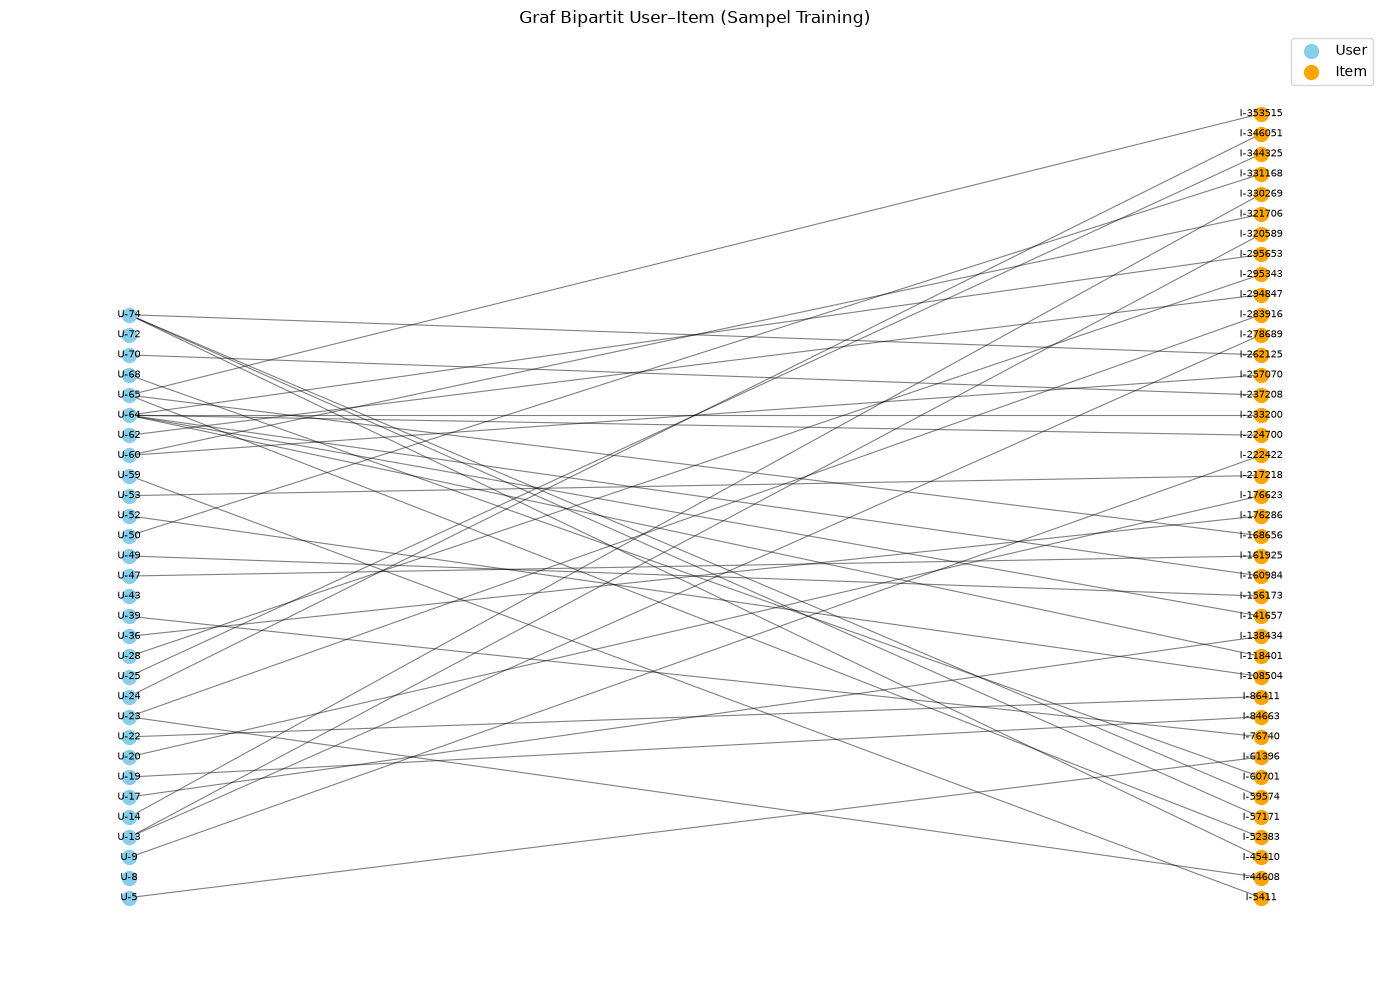

Jumlah simpul graf: 70
Jumlah relasi graf: 40


In [29]:

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Mengambil 30 User pertama
jumlah_sampel_user = 30
sampel_user_idx = np.arange(
    min(jumlah_sampel_user, X_user_item.shape[0])
)

# Mengambil interaksi dari User sampel
X_sampel = X_user_item[sampel_user_idx, :]

# Mengambil maksimal 40 Item untuk visualisasi
item_terpilih_idx = np.unique(X_sampel.indices)
item_terpilih_idx = item_terpilih_idx[:40]

# Membuat graf bipartit
G = nx.Graph()

user_plot_ids = visitor_ids[sampel_user_idx]
item_plot_ids = item_ids[item_terpilih_idx]

# Menambahkan simpul User
G.add_nodes_from(
    [f"U-{uid}" for uid in user_plot_ids],
    bipartite="user"
)

# Menambahkan simpul Item
G.add_nodes_from(
    [f"I-{iid}" for iid in item_plot_ids],
    bipartite="item"
)

# Menambahkan relasi berdasarkan interaksi VIEW
for user_idx, user_id in zip(sampel_user_idx, user_plot_ids):
    for item_idx in item_terpilih_idx:
        if X_user_item[user_idx, item_idx] > 0:
            G.add_edge(
                f"U-{user_id}",
                f"I-{item_ids[item_idx]}"
            )

# Menentukan posisi simpul
user_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "user"
]
item_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "item"
]

pos = {}
pos.update((node, (0, i)) for i, node in enumerate(user_nodes))
pos.update((node, (1, i)) for i, node in enumerate(item_nodes))

# Menggambar graf
plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=100,
    label="User"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=100,
    label="Item"
)

nx.draw_networkx_edges(G, pos, alpha=0.5, width=0.8)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.title("Graf Bipartit User–Item (Sampel Training)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul graf:", G.number_of_nodes())
print("Jumlah relasi graf:", G.number_of_edges())


### Visualisasi VSM Menggunakan NetworkX

Visualisasi hasil Vector Space Modelling (VSM) dilakukan menggunakan pustaka NetworkX untuk menggambarkan hubungan antara simpul User dan Item. Graf yang dihasilkan merupakan graf bipartit, dengan simpul User ditampilkan dalam warna biru dan simpul Item dalam warna oranye. Sisi atau *edge* yang menghubungkan kedua kelompok simpul menunjukkan adanya interaksi `VIEW` antara pengunjung dan item pada data training.

Untuk menjaga keterbacaan visualisasi dan menghindari penggunaan memori yang berlebihan, proses penggambaran dilakukan menggunakan sampel sebanyak 30 User dan maksimal 40 Item. Dengan demikian, grafik berfungsi sebagai ilustrasi struktur hubungan User–Item, bukan representasi keseluruhan simpul dan relasi dalam dataset.

Hasil visualisasi memperlihatkan bahwa seorang User dapat terhubung dengan satu atau beberapa Item, sedangkan suatu Item dapat terhubung dengan User yang melihatnya. Struktur tersebut menggambarkan pola interaksi yang menjadi dasar pembentukan matriks VSM User–Item dan dapat digunakan untuk analisis graf lebih lanjut.

### Vector Space Modelling (VSM) pada Simpul User

Vector Space Modelling (VSM) dilakukan dengan merepresentasikan simpul `Visitor` sebagai User dan simpul `Item` sebagai fitur berdasarkan interaksi `VIEW` pada data training. Hasil pembentukan matriks menghasilkan dimensi sebesar 661.487 × 169.622, yang terdiri atas 661.487 pengunjung unik dan 169.622 item unik. Matriks tersebut memiliki 994.219 pasangan User–Item unik setelah interaksi berulang pada pasangan yang sama direpresentasikan sebagai satu interaksi biner.

Total kemungkinan sel dalam matriks mencapai 112.202.747.914 sel, dengan tingkat *sparsity* sebesar 99,999114% dan kepadatan sebesar 0,000886%. Tingkat *sparsity* yang tinggi menunjukkan bahwa hanya sebagian kecil dari seluruh kemungkinan pasangan User–Item yang memiliki interaksi. Oleh karena itu, matriks disimpan menggunakan format sparse CSR (*Compressed Sparse Row*) untuk mengurangi kebutuhan memori dan mendukung pemrosesan data yang lebih efisien.

Visualisasi struktur hubungan dilakukan menggunakan NetworkX dengan mengambil sampel sebanyak 30 User dan maksimal 40 Item. Hasil visualisasi menghasilkan graf dengan 70 simpul dan 40 relasi. Simpul User ditampilkan dalam warna biru, sedangkan simpul Item ditampilkan dalam warna oranye. Relasi yang menghubungkan kedua kelompok simpul merepresentasikan interaksi `VIEW` antara pengunjung dan item.

Graf tersebut merupakan graf bipartit karena terdiri atas dua kelompok simpul yang berbeda, yaitu User dan Item, dengan relasi yang menghubungkan simpul dari kedua kelompok tersebut. Visualisasi sampel ini digunakan untuk memperlihatkan struktur hubungan secara lebih mudah dibaca, sedangkan karakteristik keseluruhan data dianalisis melalui dimensi dan jumlah pasangan unik dalam matriks VSM.

# 5. Membangun VSM Item–User

In [31]:

import numpy as np
from scipy.sparse import save_npz
import os

# 1. Membalik orientasi VSM User–Item
X_item_user = X_user_item.transpose().tocsr()

# 2. Menghitung karakteristik VSM Item–User
jumlah_item, jumlah_user = X_item_user.shape
jumlah_pasangan = X_item_user.nnz
total_sel = jumlah_item * jumlah_user
sparsity = (1 - jumlah_pasangan / total_sel) * 100
kepadatan = (jumlah_pasangan / total_sel) * 100

print("=== KARAKTERISTIK VSM ITEM–USER ===")
print("Jumlah Item:", jumlah_item)
print("Jumlah User:", jumlah_user)
print("Shape:", X_item_user.shape)
print("Jumlah pasangan Item–User unik:", jumlah_pasangan)
print(f"Total sel matriks: {total_sel:,}")
print(f"Sparsity: {sparsity:.6f}%")
print(f"Kepadatan: {kepadatan:.6f}%")

# 3. Menyimpan matriks dan indeks ID
os.makedirs("data/vsm", exist_ok=True)

save_npz("data/vsm/vsm_item_user.npz", X_item_user)
np.save("data/vsm/item_ids.npy", item_ids)
np.save("data/vsm/visitor_ids.npy", visitor_ids)

print("\nVSM Item–User berhasil disimpan.")


=== KARAKTERISTIK VSM ITEM–USER ===
Jumlah Item: 169622
Jumlah User: 661487
Shape: (169622, 661487)
Jumlah pasangan Item–User unik: 994219
Total sel matriks: 112,202,747,914
Sparsity: 99.999114%
Kepadatan: 0.000886%

VSM Item–User berhasil disimpan.


# 5.1 Membuat plot graf Item–User dengan NetworkX

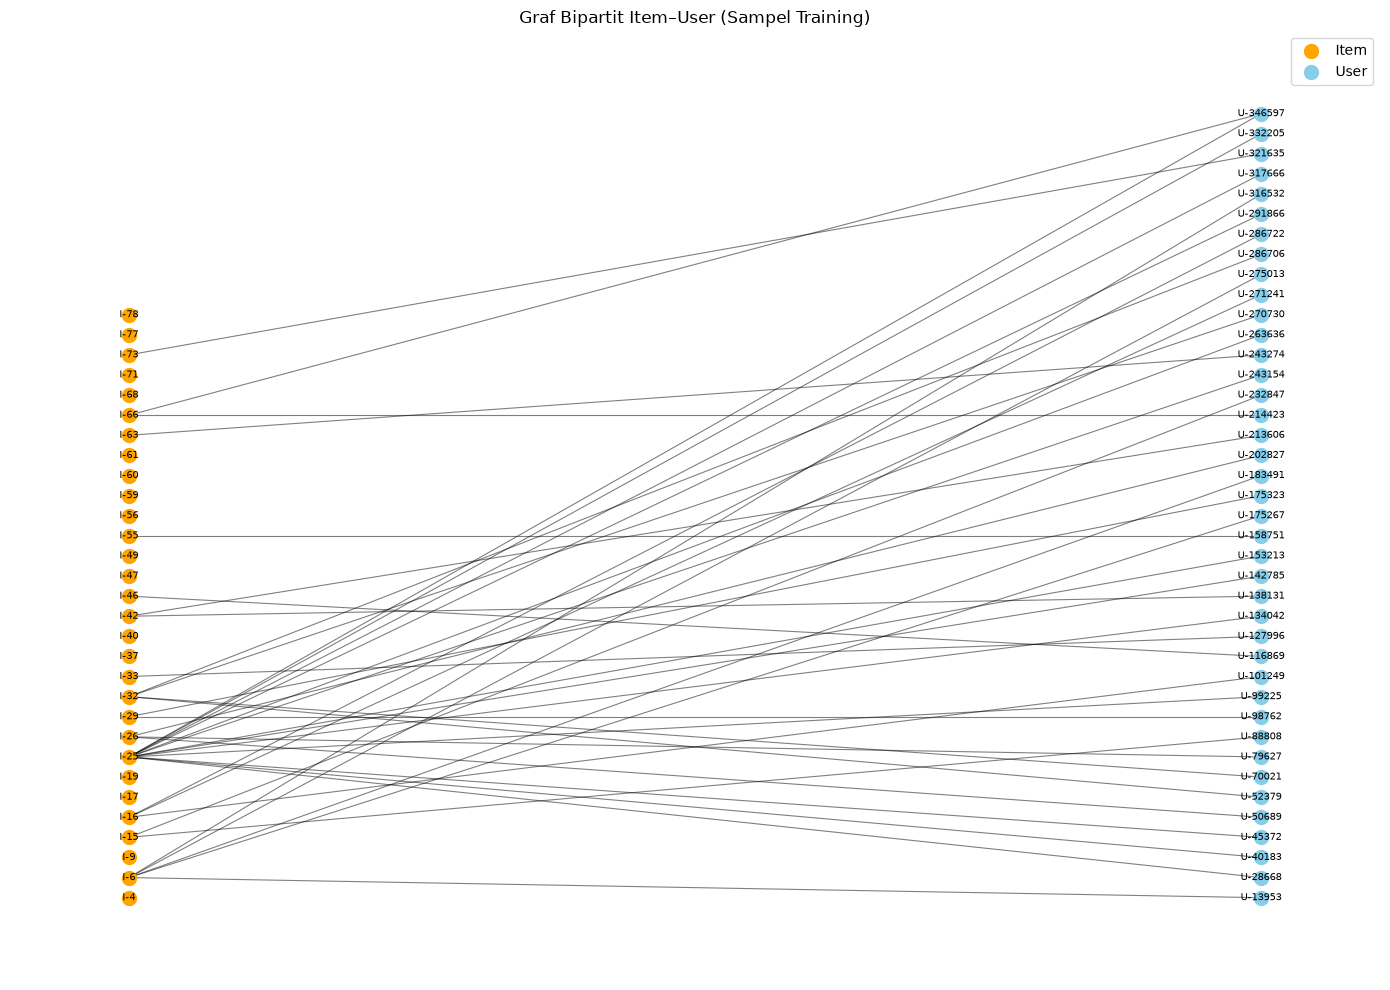

Jumlah simpul graf: 70
Jumlah relasi graf: 41


In [32]:

import networkx as nx
import matplotlib.pyplot as plt

# 1. Memilih maksimal 30 Item untuk sampel
jumlah_sampel_item = min(30, X_item_user.shape[0])
sampel_item_idx = np.arange(jumlah_sampel_item)

X_sampel_item = X_item_user[sampel_item_idx, :]

# 2. Mengambil User yang berinteraksi dengan sampel Item
user_terpilih_idx = np.unique(X_sampel_item.indices)
user_terpilih_idx = user_terpilih_idx[:40]

# Mengambil matriks sampel Item–User
X_plot = X_item_user[sampel_item_idx, :][:, user_terpilih_idx]

# 3. Membuat graf bipartit
G_item_user = nx.Graph()

item_plot_ids = item_ids[sampel_item_idx]
user_plot_ids = visitor_ids[user_terpilih_idx]

G_item_user.add_nodes_from(
    [f"I-{iid}" for iid in item_plot_ids],
    bipartite="item"
)

G_item_user.add_nodes_from(
    [f"U-{uid}" for uid in user_plot_ids],
    bipartite="user"
)

# 4. Menambahkan relasi berdasarkan nilai matriks
baris, kolom = X_plot.nonzero()

for i, j in zip(baris, kolom):
    G_item_user.add_edge(
        f"I-{item_plot_ids[i]}",
        f"U-{user_plot_ids[j]}"
    )

# 5. Mengatur posisi Item dan User
item_nodes = [
    n for n, d in G_item_user.nodes(data=True)
    if d["bipartite"] == "item"
]
user_nodes = [
    n for n, d in G_item_user.nodes(data=True)
    if d["bipartite"] == "user"
]

pos = {}
pos.update((node, (0, i)) for i, node in enumerate(item_nodes))
pos.update((node, (1, i)) for i, node in enumerate(user_nodes))

# 6. Menggambar graf
plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(
    G_item_user, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=100,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item_user, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=100,
    label="User"
)

nx.draw_networkx_edges(
    G_item_user, pos,
    alpha=0.5,
    width=0.8
)

nx.draw_networkx_labels(
    G_item_user, pos,
    font_size=7
)

plt.title("Graf Bipartit Item–User (Sampel Training)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul graf:", G_item_user.number_of_nodes())
print("Jumlah relasi graf:", G_item_user.number_of_edges())


### Vector Space Modelling pada Simpul Item

Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai Item dilakukan dengan membalik orientasi matriks User–Item menjadi matriks Item–User. Pada representasi ini, setiap baris menunjukkan satu item unik, sedangkan setiap kolom menunjukkan satu pengunjung unik. Data yang digunakan berasal dari interaksi `VIEW` pada fold training.

Hasil pembentukan matriks Item–User memiliki dimensi 169.622 × 661.487, yang terdiri atas 169.622 item unik dan 661.487 pengunjung unik. Matriks tersebut memiliki 994.219 pasangan Item–User unik. Total kemungkinan sel matriks mencapai 112.202.747.914 sel, dengan tingkat *sparsity* sebesar 99,999114% dan kepadatan sebesar 0,000886%.

Matriks disimpan dalam format sparse CSR untuk menghemat penggunaan memori karena sebagian besar pasangan Item–User tidak memiliki interaksi. Visualisasi menggunakan NetworkX dilakukan pada sebagian simpul untuk memperlihatkan hubungan antara item dan pengunjung. Pada graf, simpul Item ditampilkan dengan warna oranye dan simpul User dengan warna biru, sedangkan garis menunjukkan adanya interaksi `VIEW`.

Representasi Item–User memberikan sudut pandang berbasis item terhadap data interaksi. Representasi ini dapat digunakan sebagai dasar untuk analisis kemiripan antaritem berdasarkan pengunjung yang melihatnya, misalnya melalui proyeksi graf Item–Item.

# 6. Perbandingan Efektivitas dan Efisiensi Proyeksi Graf

Berdasarkan eksplorasi VSM pada simpul User dan Item, proyeksi graf dapat dilakukan dalam dua bentuk, yaitu proyeksi User–User dan proyeksi Item–Item. Proyeksi User–User menghubungkan dua pengunjung apabila keduanya memiliki interaksi terhadap item yang sama, sedangkan proyeksi Item–Item menghubungkan dua item apabila keduanya berinteraksi dengan pengunjung yang sama.

Dari sisi jumlah simpul, proyeksi Item–Item memiliki ukuran yang lebih kecil karena terdiri atas 169.622 simpul Item, sedangkan proyeksi User–User melibatkan 661.487 simpul User. Ukuran simpul yang lebih kecil membuat proyeksi Item–Item lebih ringkas untuk analisis yang berorientasi pada kemiripan produk. Meskipun demikian, jumlah simpul tidak menjadi satu-satunya ukuran efisiensi karena pembentukan proyeksi juga dipengaruhi oleh jumlah relasi dan waktu komputasi.

Dalam konteks dataset Retail Rocket, proyeksi Item–Item dipilih sebagai pendekatan yang lebih sesuai untuk analisis kemiripan dan rekomendasi item. Hubungan antaritem dapat dihitung menggunakan ukuran kemiripan seperti *cosine similarity*, kemudian dimanfaatkan untuk menemukan item yang memiliki pola interaksi serupa. Pendekatan ini juga dapat diintegrasikan dengan Neo4j melalui relasi `SIMILAR_TO`.

Dengan demikian, proyeksi Item–Item dinilai lebih sesuai berdasarkan tujuan analisis dan jumlah simpul yang lebih kecil. Namun, kesimpulan bahwa proyeksi tersebut lebih efisien secara komputasional perlu dikonfirmasi melalui perbandingan waktu eksekusi, jumlah relasi yang terbentuk, dan kebutuhan memori pada kedua proyeksi.

Rekomendasi proyeksi terbaik
Untuk analisis Retail Rocket dan sistem rekomendasi item, proyeksi Item–Item lebih sesuai. Alasannya:
1. Jumlah simpul lebih sedikit, yaitu 169.622 Item dibandingkan 661.487 User.
2. Hubungan antaritem dapat digunakan untuk mengidentifikasi item yang sering dilihat oleh pengunjung yang sama.
3. Proyeksi ini mendukung penghitungan cosine similarity antaritem dan pencarian item serupa sebagai kandidat rekomendasi.
4. Hasilnya dapat disimpan sebagai relasi SIMILAR_TO di Neo4j untuk analisis lebih lanjut.

Akan tetapi, proyeksi Item–Item tidak otomatis lebih cepat dalam semua kondisi. Banyaknya item yang dilihat bersama oleh pengunjung yang sama dapat menghasilkan jutaan relasi. Karena itu, efisiensi aktual harus didukung oleh pengukuran waktu eksekusi dan jumlah relasi.

# 7. Perhitungan Similarity pada Hasil Graf yang Terproyeksi dengan menggunakan Python

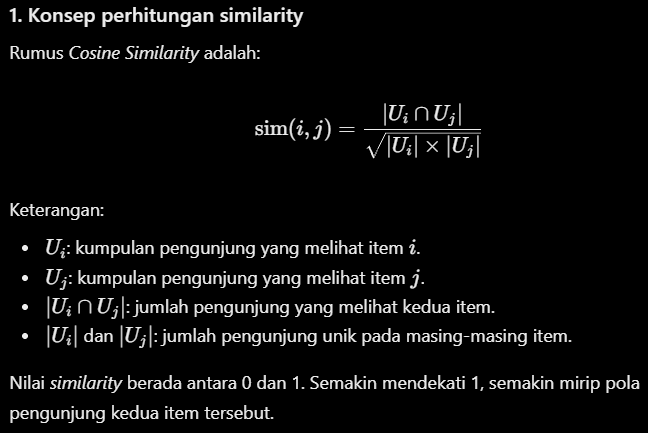

# Menghitung similarity

In [33]:

import numpy as np
from scipy.sparse import csr_matrix, diags, save_npz

# X_user_item: matriks User-Item dari data training
# Baris = Visitor, kolom = Item

# 1. Bentuk proyeksi Item-Item
P_item_item = (X_user_item.T @ X_user_item).tocsr()

# 2. Hilangkan hubungan item dengan dirinya sendiri
P_item_item.setdiag(0)
P_item_item.eliminate_zeros()

print("Shape proyeksi:", P_item_item.shape)
print("Jumlah hubungan berbobot:", P_item_item.nnz)

# 3. Hitung jumlah visitor unik untuk setiap item
jumlah_visitor_item = np.asarray(
    X_user_item.sum(axis=0)
).ravel()

# 4. Hitung norma setiap item
norma_item = np.sqrt(jumlah_visitor_item)

# Hindari pembagian dengan nol
norma_item[norma_item == 0] = 1

# 5. Hitung Cosine Similarity
inv_norma = 1.0 / norma_item
D_inv = diags(inv_norma)

similarity_item_item = (
    D_inv @ P_item_item @ D_inv
).tocsr()

# 6. Simpan hasil
save_npz(
    "data/vsm/similarity_item_item.npz",
    similarity_item_item
)

print("Shape similarity:", similarity_item_item.shape)
print("Jumlah pasangan similarity:", similarity_item_item.nnz)
print("Similarity berhasil disimpan.")


Shape proyeksi: (169622, 169622)
Jumlah hubungan berbobot: 22118370
Shape similarity: (169622, 169622)
Jumlah pasangan similarity: 22118370
Similarity berhasil disimpan.


# Menampilkan 5 item paling mirip

In [34]:

# Item yang dijadikan acuan
item_acuan = 81996

# Cari posisi item dalam VSM
posisi = np.where(item_ids == item_acuan)[0]

if len(posisi) == 0:
    print("Item acuan tidak ditemukan dalam VSM.")
else:
    idx = posisi[0]

    # Ambil similarity item acuan terhadap item lain
    skor = similarity_item_item.getrow(idx).toarray().ravel()

    # Urutkan dari similarity tertinggi
    urutan = np.argsort(skor)[::-1]

    hasil = []
    for j in urutan:
        if j == idx or skor[j] <= 0:
            continue

        hasil.append({
            "item_acuan": int(item_acuan),
            "item_mirip": int(item_ids[j]),
            "similarity": float(skor[j])
        })

        if len(hasil) == 5:
            break

    import pandas as pd
    df_similarity = pd.DataFrame(hasil)
    display(df_similarity)


,item_acuan,item_mirip,similarity
0,81996,406715,0.707107
1,81996,15878,0.707107
2,81996,69307,0.707107
3,81996,430058,0.707107
4,81996,119096,0.707107


Berdasarkan hasil perhitungan Cosine Similarity menggunakan Python pada graf hasil proyeksi Item–Item, diperoleh lima item yang memiliki kemiripan tertinggi dengan item acuan 81996, yaitu item 406715, 15878, 69307, 430058, dan 119096. Kelima item tersebut memiliki nilai similarity sebesar 0,707107.

Nilai tersebut menunjukkan adanya kemiripan pola pengunjung antara item acuan dan masing-masing item yang direkomendasikan. Perhitungan dilakukan dengan membandingkan pola pengunjung yang melihat setiap item, kemudian menormalisasi jumlah pengunjung bersama berdasarkan jumlah pengunjung unik pada kedua item. Dengan demikian, hasil ini dapat digunakan sebagai dasar untuk menemukan item-item yang memiliki pola interaksi serupa.

# (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendirirecord acuannya)!

![Screenshot 2026-10-20 142147.png](<attachment:Screenshot 2026-10-20 142147.png>)
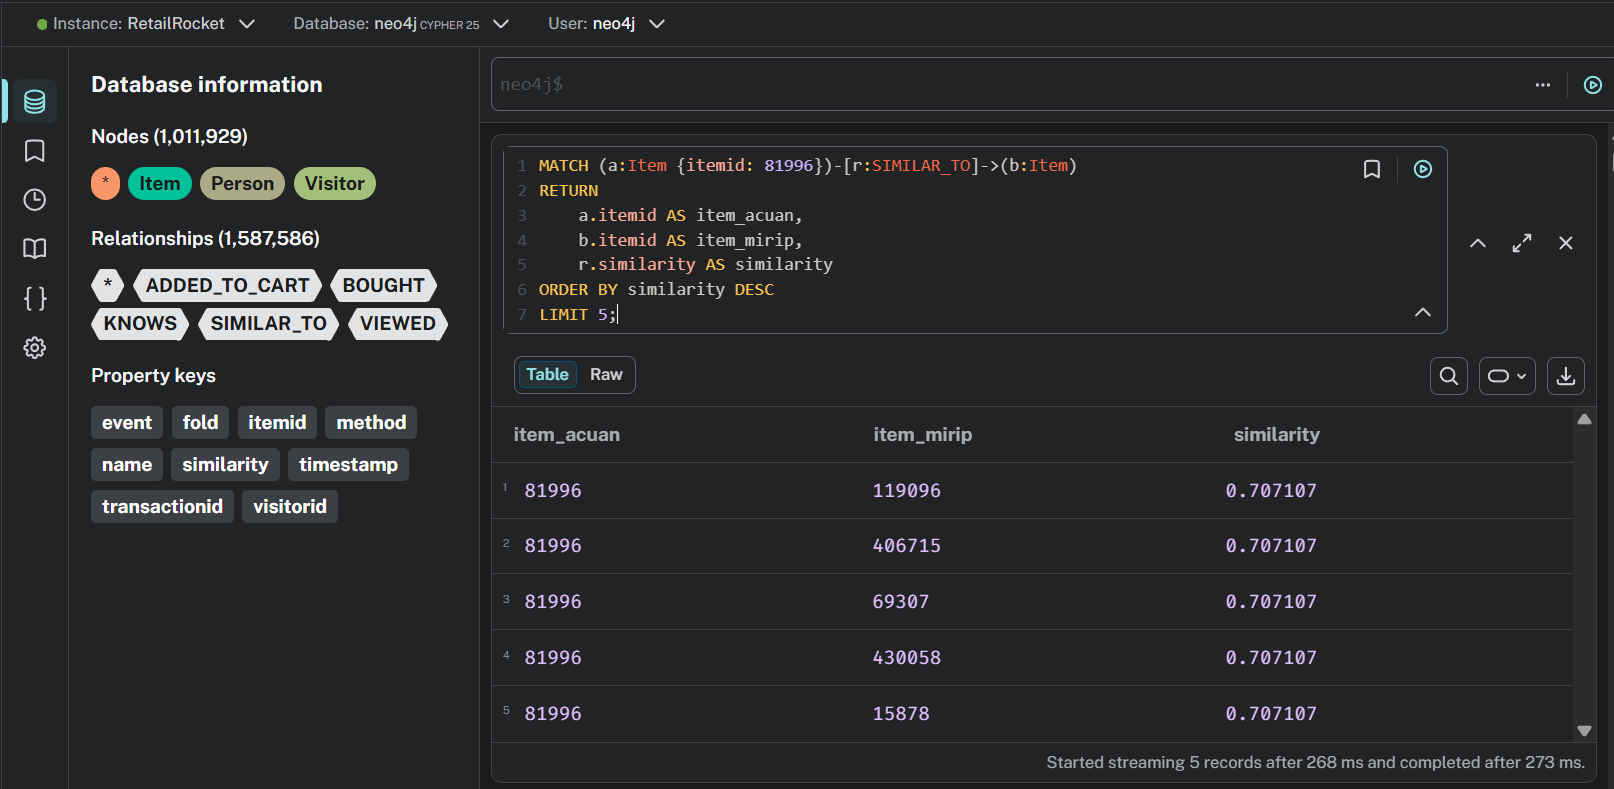

Penjelasan query
1. MATCH mencari item acuan 81996 yang memiliki relasi SIMILAR_TO menuju item lain.
2. RETURN menampilkan ID item acuan, ID item yang mirip, dan nilai similarity.
3. ORDER BY similarity DESC mengurutkan nilai similarity dari terbesar ke terkecil.
4. LIMIT 5 membatasi hasil menjadi lima record.

# (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

1. Menuliskan nilai similarity ke dalam graf

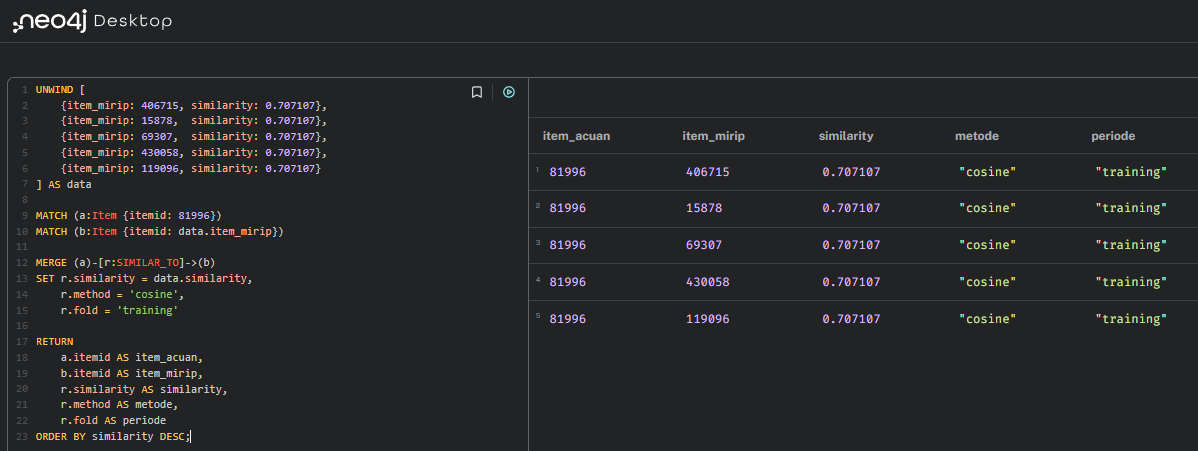

Fungsi query:
- UNWIND membuat lima data similarity menjadi baris data yang dapat diproses.
- MATCH mencari node item acuan dan node item yang mirip.
- MERGE membuat relasi SIMILAR_TO jika relasi tersebut belum ada, atau menggunakan relasi yang sudah ada dengan arah dan pasangan node yang sama.
- SET menyimpan nilai similarity beserta metode dan periode data.
- RETURN menampilkan hasil penyimpanan.
MERGE di sini mencegah pembuatan relasi duplikat untuk pasangan node dan arah relasi yang sama, tetapi tidak menghapus relasi duplikat yang mungkin sudah ada sebelumnya.

2. Memverifikasi hasil query

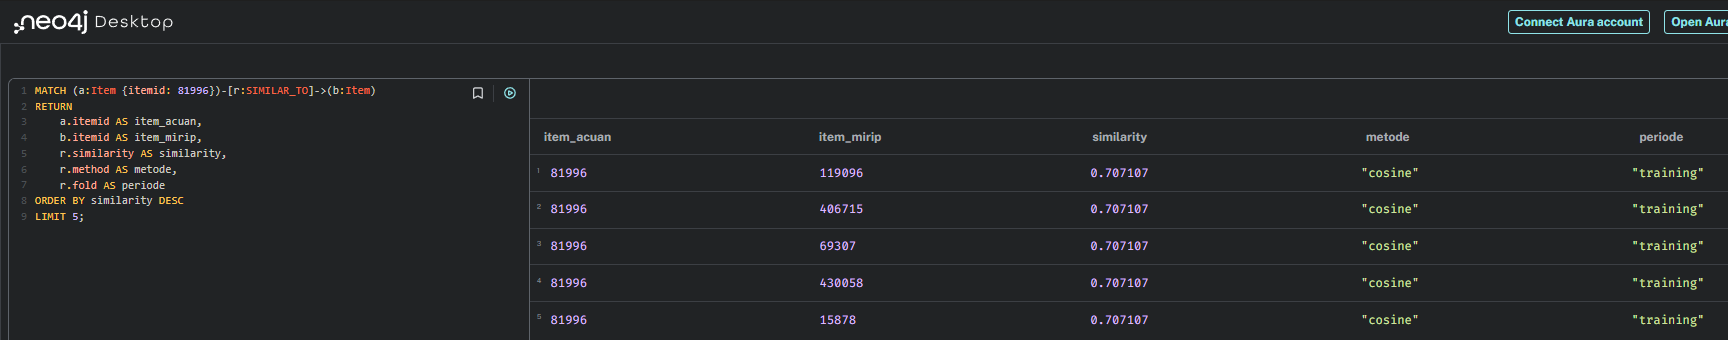

Nilai Cosine Similarity yang diperoleh dari perhitungan menggunakan Python selanjutnya disimpan pada graf Neo4j sebagai relasi SIMILAR_TO yang menghubungkan item acuan dengan item-item yang memiliki kemiripan tertinggi. Setiap relasi menyimpan properti similarity, method, dan fold, yang masing-masing menunjukkan nilai kemiripan, metode perhitungan, dan periode data yang digunakan.

Berdasarkan hasil verifikasi melalui Cypher Query, relasi antara item 81996 dan lima item terkait berhasil ditampilkan beserta nilai similarity sebesar 0.707107. Dengan demikian, hasil perhitungan Python telah direpresentasikan kembali dalam graf dan dapat digunakan pada tahap analisis rekomendasi berikutnya.

# 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudahperhitungan similarity!

1. Sebelum perhitungan similarity

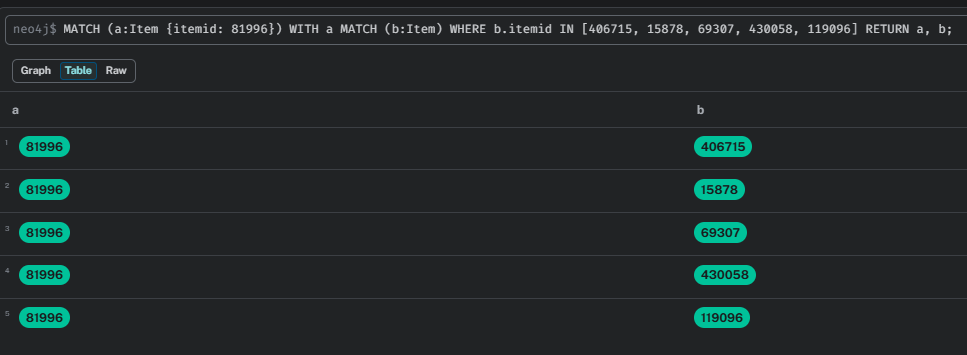

Query ini menampilkan enam node item, yaitu satu item acuan dan lima item pembanding. Karena query tidak meminta relasi di antara node-node tersebut, hasilnya memperlihatkan node tanpa hubungan SIMILAR_TO yang ditampilkan oleh query.

2. Sesudah perhitungan similarity

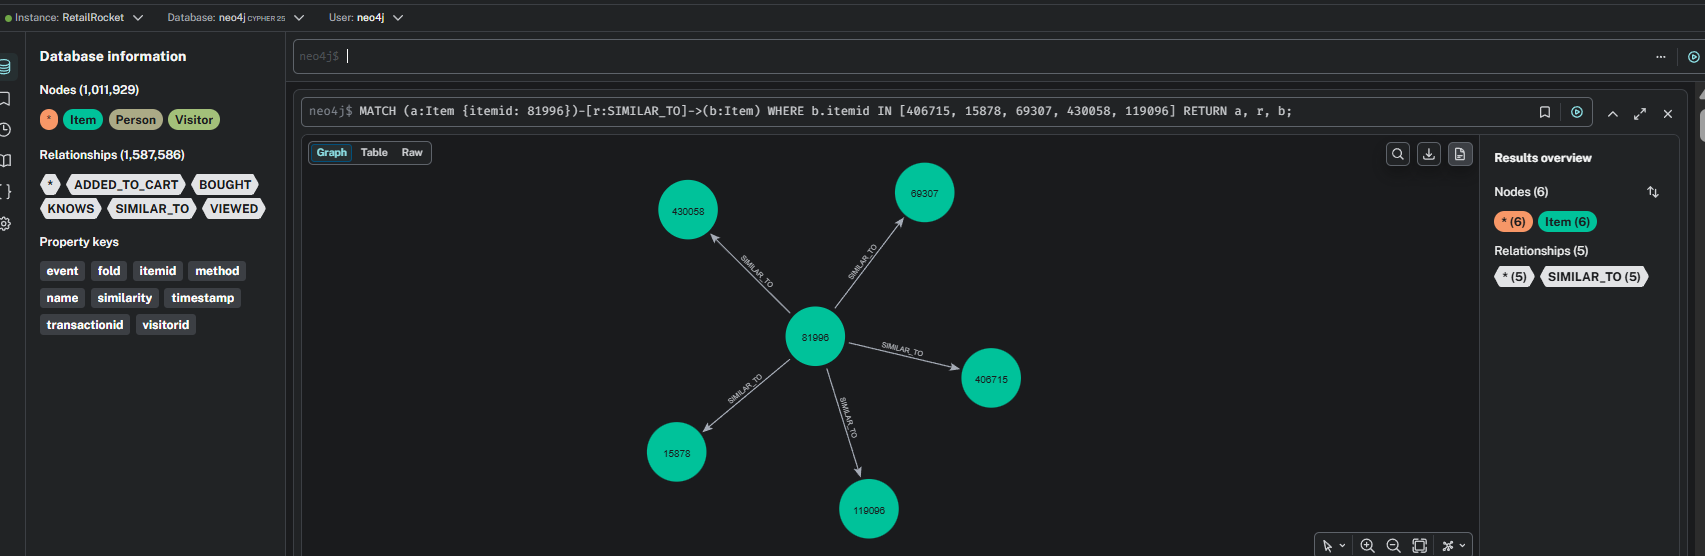

3. Query untuk memperlihatkan nilai similarity

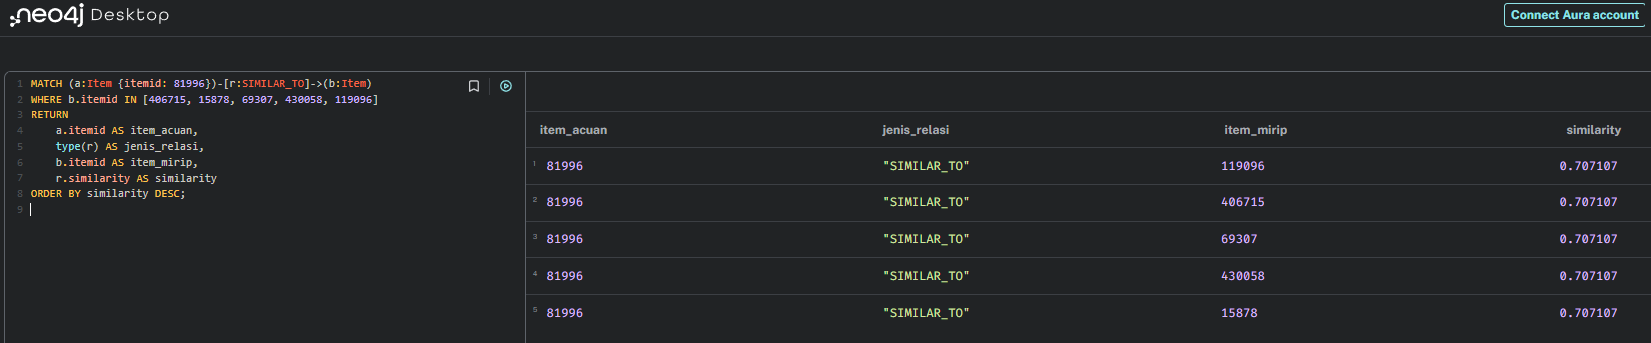

Sebelum perhitungan similarity, graf ditampilkan dengan memperlihatkan node item acuan 81996 dan lima node item pembanding. Pada tampilan tersebut, relasi kemiripan belum ditampilkan oleh query. Setelah perhitungan Cosine Similarity menggunakan Python dan penyimpanan hasil ke Neo4j, terbentuk relasi SIMILAR_TO dari item acuan menuju lima item dengan nilai similarity tertinggi, yaitu 406715, 15878, 69307, 430058, dan 119096. Masing-masing relasi memiliki nilai similarity sebesar 0.707107. Perbandingan ini menunjukkan bagaimana hasil perhitungan numerik digunakan untuk memperkaya graf dengan informasi kemiripan antar-item.

## 2.2 Analytics (Maks. skor: 55)

# 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), 

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [45]:
import numpy as np

# Daftar user kandidat yang telah ditentukan sebelumnya
eligible_users = np.sort(np.asarray(eligible_users))

# Pemilihan user secara acak dan reproducible
SEED = 42
rng = np.random.default_rng(SEED)

user_target = int(rng.choice(eligible_users))

print("Random seed:", SEED)
print("User terpilih:", user_target)

Random seed: 42
User terpilih: 125850


# Mencari lima tetangga terdekat

KNN menggunakan matriks VSM User–Item dan metrik Cosine Distance. Lima user dengan jarak terkecil dipilih sebagai tetangga terdekat.

In [46]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Memetakan ID user ke indeks matriks VSM
visitor_to_idx = {
    int(uid): idx
    for idx, uid in enumerate(visitor_ids)
}

idx_target = visitor_to_idx[user_target]

# User kandidat selain user target
candidate_users = [
    int(uid) for uid in eligible_users
    if int(uid) in visitor_to_idx
    and int(uid) != user_target
]

candidate_indices = np.array([
    visitor_to_idx[uid]
    for uid in candidate_users
])

# Matriks user kandidat
X_candidates = X_user_item[candidate_indices]

# Model KNN dengan K = 5
K = 5

model_knn = NearestNeighbors(
    n_neighbors=min(K, len(candidate_users)),
    metric="cosine",
    algorithm="brute"
)

model_knn.fit(X_candidates)

# Mencari tetangga terdekat
distances, indices = model_knn.kneighbors(
    X_user_item[idx_target],
    return_distance=True
)

# Menampilkan hasil
hasil_knn = []

for distance, posisi in zip(distances[0], indices[0]):
    uid = candidate_users[posisi]

    hasil_knn.append({
        "user_target": user_target,
        "user_tetangga": uid,
        "cosine_distance": float(distance),
        "similarity": float(1 - distance)
    })

df_knn = pd.DataFrame(hasil_knn)
display(df_knn)

,user_target,user_tetangga,cosine_distance,similarity
0,125850,821026,0.0,1.0
1,125850,815658,0.0,1.0
2,125850,215110,0.0,1.0
3,125850,1407544,1.0,0.0
4,125850,1407543,1.0,0.0


Berdasarkan hasil tersebut, user 125850 memiliki tiga tetangga dengan nilai Cosine Similarity sebesar 1,0, yaitu user 821026, 815658, dan 215110. Ketiga user tersebut memiliki pola interaksi yang identik dengan user target pada matriks VSM. Sementara itu, user 1407544 dan 1407543 memiliki nilai similarity sebesar 0,0 karena tidak mempunyai item yang sama dengan user target.

Dengan demikian, algoritma KNN berhasil mengidentifikasi lima tetangga terdekat berdasarkan kemiripan pola interaksi pengguna.

# (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

Mengambil 3 item rekomendasi

In [47]:

from collections import defaultdict
import pandas as pd

# Item yang sudah dilihat user target
idx_target = visitor_to_idx[user_target]
item_target = set(X_user_item[idx_target].indices)

# Kumpulkan item dari lima tetangga KNN
skor_item = defaultdict(float)
jumlah_tetangga_item = defaultdict(int)

for distance, posisi in zip(distances[0], indices[0]):
    uid = candidate_users[posisi]
    idx_neighbor = visitor_to_idx[uid]

    similarity = 1 - float(distance)

    for item_idx in X_user_item[idx_neighbor].indices:
        if item_idx not in item_target:
            skor_item[item_idx] += similarity
            jumlah_tetangga_item[item_idx] += 1

# Urutkan berdasarkan skor rekomendasi
ranking = sorted(
    skor_item.items(),
    key=lambda x: (x[1], jumlah_tetangga_item[x[0]]),
    reverse=True
)

# Ambil maksimal 3 item
hasil_rekomendasi = pd.DataFrame([
    {
        "itemid": int(item_ids[idx]),
        "skor_rekomendasi": round(skor, 6),
        "jumlah_tetangga": jumlah_tetangga_item[idx]
    }
    for idx, skor in ranking[:3]
])

display(hasil_rekomendasi)


,itemid,skor_rekomendasi,jumlah_tetangga
0,177522,0.0,1
1,173852,0.0,1


Berdasarkan hasil penerapan algoritma K-Nearest Neighbors dengan \(k=5\) pada user target 125850, diperoleh dua item kandidat yang belum pernah dilihat oleh user target, yaitu item 177522 dan 173852. Masing-masing item muncul pada satu tetangga dengan nilai similarity sebesar 0,0 sehingga menghasilkan skor rekomendasi berbobot sebesar 0,0. Hal ini terjadi karena tetangga yang menyumbangkan kedua item tersebut tidak memiliki kemiripan pola interaksi dengan user target.

Meskipun sistem berhasil menemukan dua kandidat, hasil ini menunjukkan bahwa rekomendasi belum cukup kuat karena kedua kandidat hanya berasal dari tetangga dengan nilai similarity nol.

# 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:(a) Hit@5

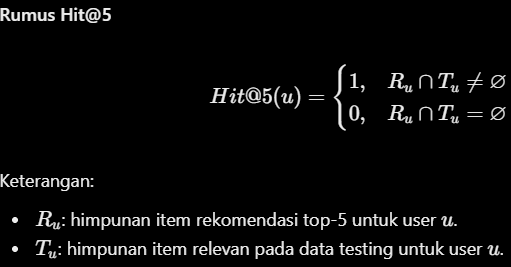

In [48]:

# Item rekomendasi dari hasil KNN
item_rekomendasi = set(
    df_top5["itemid"].head(5).astype(int)
)

# Item relevan dari data testing untuk user target
item_relevan = set(
    df_testing.loc[
        df_testing["visitorid"] == user_target,
        "itemid"
    ].astype(int).unique()
)

print("User target:", user_target)
print("Item rekomendasi:", sorted(item_rekomendasi))
print("Item relevan testing:", sorted(item_relevan))

if len(item_relevan) == 0:
    print("Hit@5: tidak dapat dievaluasi secara bermakna")
else:
    hit5 = int(
        len(item_rekomendasi.intersection(item_relevan)) > 0
    )
    print("Hit@5:", hit5)


User target: 125850
Item rekomendasi: [173852, 177522]
Item relevan testing: []
Hit@5: tidak dapat dievaluasi secara bermakna


Berdasarkan hasil tersebut, user 125850 tidak memiliki interaksi yang tercatat pada periode testing. Oleh karena itu, keberhasilan rekomendasi tidak dapat dinilai menggunakan Hit@5 untuk user ini. Kondisi tersebut bukan bukti bahwa model rekomendasi gagal, melainkan menunjukkan bahwa tidak tersedia item relevan sebagai pembanding.

# Berdasarkan hasil rekomendasi no. 1b Analytics, hitunglah: NDCG@5

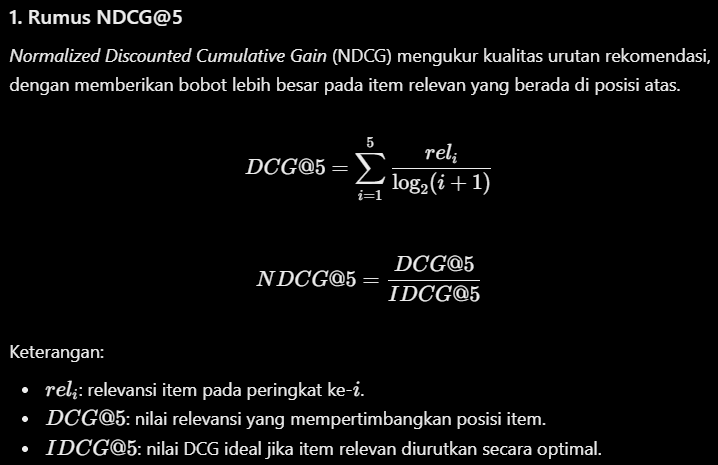

In [49]:
import numpy as np

# Urutan rekomendasi aktual dari KNN
rekomendasi_top5 = (
    df_top5["itemid"].head(5).astype(int).tolist()
)

# Item relevan user pada data testing
item_relevan = set(
    df_testing.loc[
        df_testing["visitorid"] == user_target,
        "itemid"
    ].astype(int).unique()
)

if len(item_relevan) == 0:
    print("User target:", user_target)
    print("Item rekomendasi:", rekomendasi_top5)
    print("Item relevan testing:", sorted(item_relevan))
    print("NDCG@5: tidak dapat dievaluasi secara bermakna")
else:
    relevansi = np.array([
        1 if item in item_relevan else 0
        for item in rekomendasi_top5
    ], dtype=float)

    posisi = np.arange(1, len(relevansi) + 1)
    dcg5 = np.sum(relevansi / np.log2(posisi + 1))

    jumlah_relevan = min(len(item_relevan), 5)
    relevansi_ideal = np.ones(jumlah_relevan)

    posisi_ideal = np.arange(1, jumlah_relevan + 1)
    idcg5 = np.sum(
        relevansi_ideal / np.log2(posisi_ideal + 1)
    )

    ndcg5 = dcg5 / idcg5 if idcg5 > 0 else np.nan
    print("DCG@5:", dcg5)
    print("IDCG@5:", idcg5)
    print("NDCG@5:", ndcg5)

User target: 125850
Item rekomendasi: [177522, 173852]
Item relevan testing: []
NDCG@5: tidak dapat dievaluasi secara bermakna


Hasil evaluasi menggunakan NDCG@5 pada user target 125850 menunjukkan bahwa item rekomendasi yang dihasilkan adalah item 177522 dan 173852. Namun, tidak ditemukan item relevan pada data testing untuk user tersebut. Oleh karena itu, nilai NDCG@5 tidak dapat dievaluasi secara bermakna karena tidak terdapat item relevan yang dapat digunakan sebagai dasar perhitungan *Ideal Discounted Cumulative Gain* (IDCG). Untuk memperoleh nilai evaluasi yang valid, diperlukan user target lain yang memiliki setidaknya satu interaksi pada data testing.

# Pilih user yang memiliki interaksi pada data testing

Pilih user target baru

In [50]:

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# User yang tersedia di VSM training
user_training = set(visitor_to_idx.keys())

# User yang memiliki interaksi pada data testing
user_testing = set(testing["visitorid"].astype(int).unique())

# Pilih user yang tersedia di training dan testing
kandidat_target = sorted(user_training.intersection(user_testing))

if len(kandidat_target) == 0:
    raise ValueError("Tidak ada user yang muncul pada training dan testing.")

# Pilih secara reproducible
rng = np.random.default_rng(42)
user_target = int(rng.choice(kandidat_target))

# Item relevan dari data testing
item_relevan = set(
    testing.loc[
        testing["visitorid"].astype(int) == user_target,
        "itemid"
    ].astype(int)
)

print("User target:", user_target)
print("Jumlah item relevan testing:", len(item_relevan))
print("Item relevan:", sorted(item_relevan))


User target: 128913
Jumlah item relevan testing: 1
Item relevan: [449130]


KNN dan buat rekomendasi Top-5

In [57]:

# Kandidat tetangga harus tersedia dalam VSM
candidate_users = sorted(
    set(map(int, eligible_users)).intersection(user_training)
    - {user_target}
)

candidate_indices = np.array([
    visitor_to_idx[uid] for uid in candidate_users
])

X_candidates = X_user_item[candidate_indices]

K = 5
model_knn = NearestNeighbors(
    n_neighbors=min(K, len(candidate_users)),
    metric="cosine",
    algorithm="brute"
)
model_knn.fit(X_candidates)

distances, indices = model_knn.kneighbors(
    X_user_item[visitor_to_idx[user_target]],
    return_distance=True
)

# Ambil tetangga dan similarity


# Pastikan candidate_users dan indices berasal dari model KNN yang sama
neighbors = []

for distance, idx in zip(distances[0], indices[0]):
    neighbor_id = int(candidate_users[int(idx)])

    neighbors.append({
        "visitorid": neighbor_id,
        "distance": float(distance),
        "similarity": float(1 - distance)
    })

df_neighbors = pd.DataFrame(neighbors)

display(df_neighbors)


# Hitung skor item dari tetangga berdasarkan similarity
seen_items = set(
    X_user_item[visitor_to_idx[user_target]].indices
)

scores = {}

for neighbor in neighbors:
    neighbor_id = neighbor["visitorid"]
    neighbor_idx = visitor_to_idx[neighbor_id]
    neighbor_items = X_user_item[neighbor_idx].indices

    for item_idx in neighbor_items:
        if item_idx not in seen_items:
            item_id = int(item_ids[item_idx])
            scores[item_id] = (
                scores.get(item_id, 0.0)
                + neighbor["similarity"]
            )

# Urutkan skor tertinggi; item ID menjadi pemecah seri
ranking = sorted(
    scores.items(),
    key=lambda x: (-x[1], x[0])
)[:5]

rekomendasi = [item_id for item_id, score in ranking]

df_rekomendasi = pd.DataFrame(
    ranking, columns=["itemid", "skor"]
)

print("User target:", user_target)
print("Item rekomendasi:", rekomendasi)
display(df_rekomendasi)


,visitorid,distance,similarity
0,938006,2.220446e-16,1.000000
1,1057586,2.928932e-01,0.707107
2,978414,2.928932e-01,0.707107
3,884329,2.928932e-01,0.707107
4,867370,2.928932e-01,0.707107


User target: 128913
Item rekomendasi: []


,itemid,skor


In [58]:

# Fallback jika KNN tidak menghasilkan kandidat rekomendasi
if len(scores) == 0:
    print("KNN tidak menghasilkan kandidat. Menggunakan fallback item populer.")

    # Hitung popularitas item dari data training
    popular_items = (
        training.groupby("itemid")
        .size()
        .sort_values(ascending=False)
    )

    fallback_ranking = []

    for item_id, jumlah_interaksi in popular_items.items():
        item_id = int(item_id)

        # Jangan rekomendasikan item yang sudah dilihat target
        if item_id not in seen_items:
            fallback_ranking.append(
                (item_id, int(jumlah_interaksi))
            )

        if len(fallback_ranking) == 5:
            break

    df_rekomendasi = pd.DataFrame(
        fallback_ranking,
        columns=["itemid", "skor_popularitas"]
    )

    rekomendasi = df_rekomendasi["itemid"].tolist()

else:
    df_rekomendasi = pd.DataFrame(
        ranking,
        columns=["itemid", "skor"]
    )

    rekomendasi = df_rekomendasi["itemid"].tolist()

print("User target:", user_target)
print("Metode rekomendasi:",
      "Fallback Popularitas" if len(scores) == 0 else "KNN")
print("Item rekomendasi:", rekomendasi)
display(df_rekomendasi)


KNN tidak menghasilkan kandidat. Menggunakan fallback item populer.
User target: 128913
Metode rekomendasi: Fallback Popularitas
Item rekomendasi: [5411, 309778, 370653, 461686, 257040]


,itemid,skor_popularitas
0,5411,1726
1,309778,1281
2,370653,1060
3,461686,1023
4,257040,1015


In [59]:

import numpy as np

# Item relevan berdasarkan interaksi user pada data testing
item_relevan = set(
    testing.loc[
        testing["visitorid"].astype(int) == int(user_target),
        "itemid"
    ].astype(int)
)

# Rekomendasi yang sudah dihasilkan (KNN atau fallback)
top5 = rekomendasi[:5]

# Hit@5
hit_at_5 = (
    int(any(item in item_relevan for item in top5))
    if item_relevan else None
)

# NDCG@5 dengan relevansi biner
if len(item_relevan) == 0:
    ndcg_at_5 = None
else:
    relevansi = [
        1 if item in item_relevan else 0
        for item in top5
    ]

    dcg = sum(
        rel / np.log2(pos + 2)
        for pos, rel in enumerate(relevansi)
    )

    idcg = sum(
        1 / np.log2(pos + 2)
        for pos in range(min(len(item_relevan), 5))
    )

    ndcg_at_5 = dcg / idcg if idcg > 0 else None

print("User target:", user_target)
print("Metode rekomendasi:",
      "Fallback Popularitas" if len(scores) == 0 else "KNN")
print("Item rekomendasi Top-5:", top5)
print("Item relevan testing:", sorted(item_relevan))
print("Hit@5:",
      hit_at_5 if hit_at_5 is not None else "Tidak dapat dievaluasi")
print("NDCG@5:",
      round(ndcg_at_5, 4) if ndcg_at_5 is not None else "Tidak dapat dievaluasi")


User target: 128913
Metode rekomendasi: Fallback Popularitas
Item rekomendasi Top-5: [5411, 309778, 370653, 461686, 257040]
Item relevan testing: [449130]
Hit@5: 0
NDCG@5: 0.0


Berdasarkan hasil evaluasi pada user target 128913, sistem menghasilkan lima rekomendasi menggunakan metode fallback popularitas karena metode K-Nearest Neighbors (KNN) tidak menghasilkan kandidat item baru. Lima item yang direkomendasikan adalah 5411, 309778, 370653, 461686, dan 257040. Sementara itu, item relevan yang tercatat pada data testing adalah item 449130.

Hasil evaluasi menunjukkan nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,0000. Hal ini menunjukkan bahwa item relevan dari data testing tidak berhasil ditemukan dalam lima rekomendasi teratas. Nilai NDCG@5 sebesar nol juga menunjukkan bahwa tidak terdapat item relevan pada daftar rekomendasi yang dapat memperoleh nilai keuntungan berdasarkan posisinya. Hasil ini berlaku untuk user target yang diuji dan tidak dapat langsung digeneralisasikan sebagai kinerja keseluruhan sistem rekomendasi.

Perlu diperhatikan bahwa hasil tersebut berasal dari fallback popularitas, bukan rekomendasi KNN murni. Oleh karena itu, hasil ini perlu dibedakan dalam pelaporan agar metode yang digunakan dan kinerja evaluasinya dapat dijelaskan secara tepat.

# UTS Selesai 

## Proses Pengerjaan Testing Awal : 

### Interpretasi Hasil Pembagian Periode Data

Berdasarkan hasil pemeriksaan periode data, dataset Retail Rocket terbagi menjadi dua bagian, yaitu data training dan data testing. Data training mencakup periode 19 Mei sampai 19 Juli 2015 dengan total 1.286.531 event, sedangkan data testing mencakup periode 28 Juli sampai 12 Agustus 2015 dengan total 301.047 event.

Pada data training, aktivitas *view* mendominasi dengan 1.244.923 event, diikuti aktivitas *addtocart* sebanyak 31.318 event dan *transaction* sebanyak 10.290 event. Pola serupa ditemukan pada data testing, yaitu 290.217 event *view*, 8.227 event *addtocart*, dan 2.603 event *transaction*.

Hasil tersebut menunjukkan bahwa aktivitas melihat barang jauh lebih sering terjadi dibandingkan aktivitas menambahkan barang ke keranjang maupun transaksi pembelian. Kondisi ini menggambarkan karakteristik dataset e-commerce yang memiliki jumlah interaksi pada tahap penjelajahan lebih besar daripada interaksi yang menunjukkan niat pembelian atau pembelian aktual.

Data training digunakan untuk membangun representasi graf, membentuk proyeksi antarbarang, dan menghitung *cosine similarity*. Sementara itu, data testing digunakan untuk mengevaluasi rekomendasi pada periode yang lebih akhir. Pemisahan waktu ini membantu menghindari penggunaan data masa depan dalam pembentukan model. Terdapat jeda waktu antara kedua periode, yaitu 20–27 Juli 2015, sehingga kedua fold tidak saling tumpang tindih.

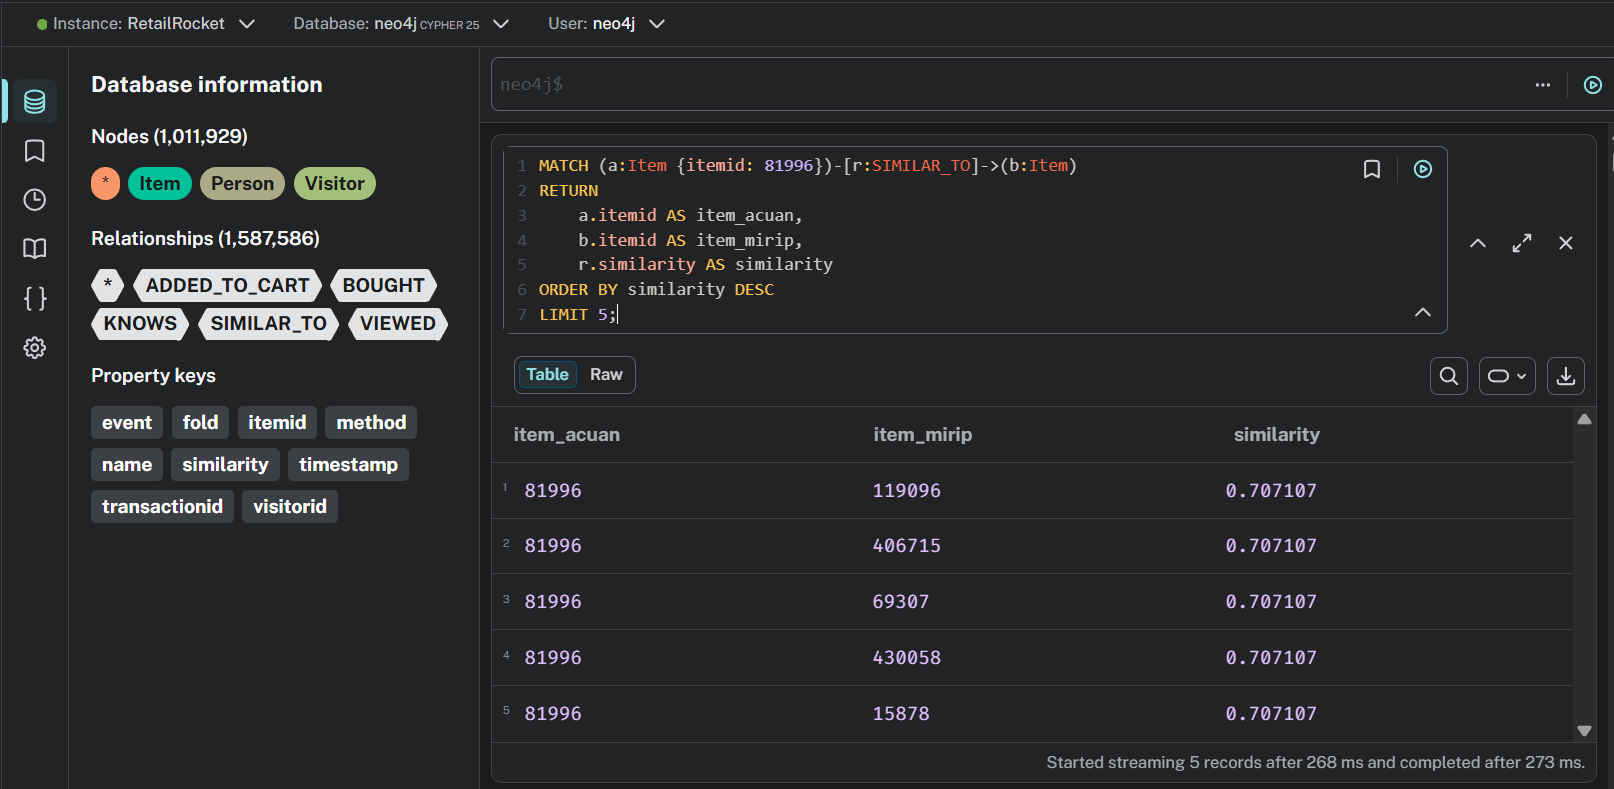

### Skrip sumber: `siapkan_fold_data.py`

In [ ]:
# Sumber: siapkan_fold_data.py

import pandas as pd
from pathlib import Path

# Lokasi file sumber
source = Path("data/events.csv")
output_dir = Path("data/folds")
output_dir.mkdir(parents=True, exist_ok=True)

# Periode UTC
training_start = pd.Timestamp("2015-05-19 00:00:00", tz="UTC")
training_end = pd.Timestamp("2015-07-20 00:00:00", tz="UTC")

testing_start = pd.Timestamp("2015-07-28 00:00:00", tz="UTC")
testing_end = pd.Timestamp("2015-08-13 00:00:00", tz="UTC")

# Baca CSV per 200.000 baris agar hemat memori
training_count = 0
testing_count = 0

for chunk in pd.read_csv(source, chunksize=200_000):
    timestamps = pd.to_datetime(
        chunk["timestamp"], unit="ms", utc=True
    )

    training = chunk[
        (timestamps >= training_start) &
        (timestamps < training_end)
    ]

    testing = chunk[
        (timestamps >= testing_start) &
        (timestamps < testing_end)
    ]

    if not training.empty:
        path = output_dir / "training.csv"
        training.to_csv(
            path,
            mode="a" if training_count else "w",
            header=(training_count == 0),
            index=False
        )
        training_count += len(training)

    if not testing.empty:
        path = output_dir / "testing.csv"
        testing.to_csv(
            path,
            mode="a" if testing_count else "w",
            header=(testing_count == 0),
            index=False
        )
        testing_count += len(testing)

    print(
        f"Training: {training_count:,} | "
        f"Testing: {testing_count:,}"
    )

print("\nSelesai.")
print("Total training:", training_count)
print("Total testing:", testing_count)
print("File tersimpan di:", output_dir.resolve())


### Proses Pembentukan Data Training dan Testing

Pembentukan data *training* dan *testing* dilakukan dengan menyaring dataset Retail Rocket berdasarkan rentang waktu menggunakan kolom `timestamp`, yang dikonversi dari Unix timestamp dalam milidetik ke format tanggal dan waktu UTC. Data diproses secara bertahap menggunakan `chunksize=200.000` untuk mengurangi penggunaan memori selama pembacaan dataset.

Data training mencakup periode 19 Mei sampai 19 Juli 2015, sedangkan data testing mencakup periode 28 Juli sampai 12 Agustus 2015. Kedua periode disimpan secara terpisah dalam file `training.csv` dan `testing.csv` pada direktori `data/folds`.

Berdasarkan hasil pemeriksaan periode sebelumnya, file training berisi 1.286.531 event dan file testing berisi 301.047 event. Pemisahan ini digunakan untuk membangun graf berdasarkan data training dan mengevaluasi rekomendasi menggunakan data testing pada periode yang lebih akhir.

## 1.3 Import data ke Neo4j

### Skrip sumber: `import_folds_neo4j.py`

In [ ]:
# Sumber: import_folds_neo4j.py

import argparse
import getpass
from pathlib import Path

import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase


DATA_DIR = Path("data/folds")
BATCH_SIZE = 5000

RELATION_TYPES = {
    "view": "VIEWED",
    "addtocart": "ADDED_TO_CART",
    "transaction": "BOUGHT",
}


def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
    """).consume()


def clear_old_relationships(session):
    print("Menghapus relasi lama dari database UTS...")
    session.run("""
        MATCH ()-[r]->()
        DELETE r
    """).consume()
    print("Relasi lama berhasil dibersihkan.")


def import_fold(session, csv_path, fold_name):
    print(f"\nMemproses {fold_name}: {csv_path}")

    if not csv_path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {csv_path}")

    total = 0

    for chunk in tqdm(
        pd.read_csv(csv_path, chunksize=BATCH_SIZE),
        desc=f"Impor {fold_name}"
    ):
        rows = []

        for row in chunk.to_dict(orient="records"):
            event = row["event"]

            if event not in RELATION_TYPES:
                continue

            transaction_id = row.get("transactionid")

            if pd.isna(transaction_id):
                transaction_id = None
            else:
                transaction_id = int(transaction_id)

            rows.append({
                "visitorid": int(row["visitorid"]),
                "itemid": int(row["itemid"]),
                "event": event,
                "timestamp": int(row["timestamp"]),
                "transactionid": transaction_id,
                "fold": fold_name,
            })

        if not rows:
            continue

        query = """
        UNWIND $rows AS row

        MERGE (v:Visitor {visitorid: row.visitorid})
        MERGE (i:Item {itemid: row.itemid})

        WITH v, i, row
        CALL {
            WITH v, i, row
            WITH v, i, row
            WHERE row.event = 'view'
            CREATE (v)-[:VIEWED {
                timestamp: row.timestamp,
                fold: row.fold
            }]->(i)
            RETURN 1 AS created

            UNION

            WITH v, i, row
            WITH v, i, row
            WHERE row.event = 'addtocart'
            CREATE (v)-[:ADDED_TO_CART {
                timestamp: row.timestamp,
                fold: row.fold
            }]->(i)
            RETURN 1 AS created

            UNION

            WITH v, i, row
            WITH v, i, row
            WHERE row.event = 'transaction'
            CREATE (v)-[:BOUGHT {
                timestamp: row.timestamp,
                transactionid: row.transactionid,
                fold: row.fold
            }]->(i)
            RETURN 1 AS created
        }
        RETURN count(*) AS created_count
        """

        result = session.run(query, rows=rows)
        result.consume()
        total += len(rows)

    print(f"Event {fold_name} diproses: {total:,}")
    return total


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--password",
        default=None,
        help="Password Neo4j (opsional)"
    )
    parser.add_argument(
        "--uri",
        default="bolt://127.0.0.1:7687"
    )
    parser.add_argument(
        "--user",
        default="neo4j"
    )
    parser.add_argument(
        "--clear-old",
        action="store_true",
        help="Hapus semua relasi lama sebelum impor"
    )

    args = parser.parse_args()

    password = args.password

    if password is None:
        password = getpass.getpass("Masukkan password Neo4j: ")

    driver = GraphDatabase.driver(
        args.uri,
        auth=(args.user, password)
    )

    try:
        driver.verify_connectivity()
        print("Koneksi Neo4j berhasil.")

        with driver.session(database="neo4j") as session:
            create_constraints(session)

            if args.clear_old:
                clear_old_relationships(session)

            training_total = import_fold(
                session,
                DATA_DIR / "training.csv",
                "training"
            )

            testing_total = import_fold(
                session,
                DATA_DIR / "testing.csv",
                "testing"
            )

        print("\nImpor selesai.")
        print(f"Training: {training_total:,}")
        print(f"Testing: {testing_total:,}")

    finally:
        driver.close()


if __name__ == "__main__":
    main()


### Proses Import Data ke Neo4j

Data training dan testing diimpor ke Neo4j menggunakan Python Driver dan Cypher. Proses dilakukan secara bertahap dengan ukuran batch 5.000 baris untuk membantu mengelola penggunaan memori dan pengiriman data ke database.

Setiap pengguna direpresentasikan sebagai node `Visitor`, sedangkan setiap barang direpresentasikan sebagai node `Item`. Relasi dibentuk berdasarkan jenis aktivitas pengguna, yaitu `VIEWED` untuk melihat barang, `ADDED_TO_CART` untuk menambahkan barang ke keranjang, dan `BOUGHT` untuk transaksi pembelian. Setiap relasi menyimpan informasi periode data melalui properti `fold`, sehingga interaksi training dan testing dapat dibedakan.

Constraint unik pada `visitorid` dan `itemid` digunakan untuk mencegah terbentuknya node pengguna atau barang dengan ID yang sama. Sementara itu, relasi menyimpan informasi waktu interaksi dan, untuk transaksi pembelian, ID transaksi jika tersedia.

Hasil pemeriksaan di Neo4j menunjukkan bahwa data training terdiri atas 1.286.531 relasi interaksi, sedangkan data testing terdiri atas 301.047 relasi interaksi. Dengan demikian, graf menyimpan 1.587.578 relasi interaksi dari kedua periode sebelum penambahan relasi `SIMILAR_TO` untuk hasil analisis kemiripan barang.

## 2.1 Wrangling & EDA

### Skrip sumber: `cek_vsm.py`

In [1]:
# Sumber: cek_vsm.py
from neo4j import GraphDatabase
import getpass

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

try:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        result = session.run("""
            MATCH (v:Visitor)-[r:VIEWED]->(i:Item)
            WHERE r.fold = 'training'
            RETURN count(r) AS jumlah_event,
                   count(DISTINCT v) AS jumlah_visitor,
                   count(DISTINCT i) AS jumlah_item
        """)

        print(result.single().data())

finally:
    driver.close()

C:\Users\nafilahanum.alhs\AppData\Local\Temp\ipykernel_22820\1126192707.py:15: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


{'jumlah_event': 1244923, 'jumlah_visitor': 661487, 'jumlah_item': 169622}


### Interpretasi Hasil Pemeriksaan Graf Training

Berdasarkan hasil pemeriksaan melalui Neo4j, terdapat 1.244.923 event `VIEWED` pada periode training yang melibatkan 661.487 pengguna unik (`Visitor`) dan 169.622 barang unik (`Item`). Hasil ini menunjukkan bahwa data interaksi training berhasil tersimpan dan dapat diakses melalui kueri Cypher.

Jumlah event lebih besar daripada jumlah pengguna maupun barang karena satu pengguna dapat melihat beberapa barang dan satu barang dapat dilihat oleh banyak pengguna. Selain itu, satu pasangan pengguna dan barang dapat memiliki lebih dari satu event interaksi. Oleh karena itu, jumlah event tidak sama dengan jumlah pasangan pengguna dan barang yang unik.

Data ini digunakan sebagai dasar pembentukan VSM User-Item. Setelah pasangan pengguna dan barang yang berulang digabungkan dalam representasi matriks biner, diperoleh 994.219 pasangan unik yang memiliki interaksi *view*.

### Skrip sumber: `vsm_user_item.py`

In [ ]:
# Sumber: vsm_user_item.py
from scipy.sparse import csr_matrix, save_npz
from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
import pandas as pd
import numpy as np
import getpass

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

try:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        result = session.run("""
            MATCH (v:Visitor)-[r:VIEWED]->(i:Item)
            WHERE r.fold = 'training'
            RETURN v.visitorid AS visitorid,
                   i.itemid AS itemid
        """)

        df = pd.DataFrame(
            [record.data() for record in result]
        )

    print("Jumlah baris interaksi:", len(df))

    # Membuat indeks untuk setiap visitor dan item
    visitor_ids = pd.Index(df["visitorid"].unique())
    item_ids = pd.Index(df["itemid"].unique())
    # Simpan pemetaan indeks ke ID asli
    np.save("visitor_ids.npy", visitor_ids.to_numpy())
    np.save("item_ids.npy", item_ids.to_numpy())

    print("Pemetaan visitor dan item berhasil disimpan.")
    row = visitor_ids.get_indexer(df["visitorid"])
    col = item_ids.get_indexer(df["itemid"])

    # Matriks biner: 1 jika visitor pernah melihat item
    data = [1] * len(df)

    vsm = csr_matrix(
        (data, (row, col)),
        shape=(len(visitor_ids), len(item_ids))
    )

    # Ubah menjadi biner jika ada interaksi berulang
    vsm.data[:] = 1

    print("Jumlah visitor:", len(visitor_ids))
    print("Jumlah item:", len(item_ids))
    print("Shape VSM:", vsm.shape)
    print("Jumlah pasangan visitor-item:", vsm.nnz)
    print("Tipe matriks:", type(vsm).__name__)
    save_npz("vsm_user_item.npz", vsm)
    print("VSM berhasil disimpan ke vsm_user_item.npz")

finally:
    driver.close()


### Pembentukan Vector Space Model (VSM) User-Item

VSM User-Item dibentuk berdasarkan relasi `VIEWED` pada data training yang tersimpan di Neo4j. Setiap baris matriks merepresentasikan pengguna (`Visitor`), sedangkan setiap kolom merepresentasikan barang (`Item`). Nilai 1 menunjukkan bahwa pengguna pernah melihat barang tersebut, sedangkan nilai 0 menunjukkan tidak adanya interaksi *view* yang tercatat pada pasangan tersebut.

Hasil pembentukan matriks menghasilkan ukuran **(661.487, 169.622)** dengan **994.219 pasangan pengguna dan barang unik** yang memiliki interaksi. Matriks disimpan menggunakan format sparse `csr_matrix` untuk menghemat penyimpanan karena sebagian besar kombinasi pengguna dan barang tidak memiliki interaksi.

Jumlah event `VIEWED` pada data training adalah 1.244.923, tetapi jumlah pasangan unik dalam matriks hanya 994.219. Perbedaan ini terjadi karena satu pengguna dapat melihat barang yang sama berulang kali. Dalam matriks biner, interaksi berulang tersebut direpresentasikan sebagai satu nilai 1. Dengan demikian, VSM menggambarkan keberadaan interaksi, bukan frekuensi interaksi.

### Skrip sumber: `vsm_item_user.py`

In [2]:
# Sumber: vsm_item_user.py

from scipy.sparse import load_npz, save_npz

# Memuat VSM User-Item yang sudah disimpan
vsm_user_item = load_npz("vsm_user_item.npz")

# Membalik orientasi: baris menjadi item, kolom menjadi visitor
vsm_item_user = vsm_user_item.transpose().tocsr()

# Simpan VSM Item-User
save_npz("vsm_item_user.npz", vsm_item_user)

print("Shape VSM User-Item:", vsm_user_item.shape)
print("Shape VSM Item-User:", vsm_item_user.shape)
print("Jumlah pasangan item-visitor:", vsm_item_user.nnz)
print("Tipe matriks:", type(vsm_item_user).__name__)
print("VSM Item-User berhasil disimpan.")


Shape VSM User-Item: (661487, 169622)
Shape VSM Item-User: (169622, 661487)
Jumlah pasangan item-visitor: 994219
Tipe matriks: csr_matrix
VSM Item-User berhasil disimpan.


### Hasil Pembentukan VSM Item-User

VSM Item-User merupakan transpose dari VSM User-Item. Pada matriks ini, setiap baris merepresentasikan barang (*Item*), sedangkan setiap kolom merepresentasikan pengguna (*Visitor*). Pembalikan orientasi ini memungkinkan analisis hubungan kemiripan antarbarang berdasarkan kesamaan pengguna yang melihatnya.

Matriks VSM Item-User memiliki ukuran **(169.622, 661.487)** dengan **994.219 elemen nonzero** dan menggunakan format `csr_matrix`. Jumlah elemen nonzero sama dengan VSM User-Item karena proses transpose tidak mengubah jumlah pasangan interaksi. Perbedaan orientasi matriks memungkinkan pembentukan proyeksi graf Item-Item untuk mengidentifikasi barang yang memiliki pola interaksi serupa.

## 4. Analisis dan proyeksi graf

### Skrip sumber: `analisis_proyeksi.py`

In [3]:
# Sumber: analisis_proyeksi.py

from scipy.sparse import load_npz
import numpy as np

# Memuat matriks interaksi User-Item
vsm = load_npz("vsm_user_item.npz")

jumlah_visitor, jumlah_item = vsm.shape
jumlah_interaksi = vsm.nnz

# Derajat setiap visitor: jumlah item yang pernah dilihat
derajat_visitor = np.diff(vsm.indptr)

# Derajat setiap item: jumlah visitor yang pernah melihatnya
derajat_item = np.asarray(vsm.sum(axis=0)).ravel()

print("=== INFORMASI GRAF BIPARTIT TRAINING ===")
print("Jumlah visitor:", jumlah_visitor)
print("Jumlah item:", jumlah_item)
print("Jumlah sisi visitor-item:", jumlah_interaksi)

print("\n=== STATISTIK VISITOR ===")
print("Rata-rata item yang dilihat per visitor:",
      round(derajat_visitor.mean(), 2))
print("Maksimum item yang dilihat seorang visitor:",
      int(derajat_visitor.max()))

print("\n=== STATISTIK ITEM ===")
print("Rata-rata visitor per item:",
      round(derajat_item.mean(), 2))
print("Maksimum visitor yang melihat satu item:",
      int(derajat_item.max()))

# Estimasi jumlah sisi pada proyeksi Item-Item.
# Setiap visitor yang melihat d item dapat membentuk d*(d-1)/2
# pasangan item, sebelum pasangan yang sama dideduplikasi.
estimasi_pasangan = np.sum(
    derajat_visitor * (derajat_visitor - 1) // 2,
    dtype=np.int64
)

print("\n=== ESTIMASI PROYEKSI ITEM-ITEM ===")
print("Jumlah pasangan item yang terbentuk sebelum deduplikasi:",
      int(estimasi_pasangan))


print("\n=== DISTRIBUSI DERAJAT VISITOR ===")

for persentil in [50, 75, 90, 95, 99, 99.9]:
    nilai = np.percentile(derajat_visitor, persentil)
    print(f"Persentil {persentil}%: {nilai:.0f} item")

for batas in [10, 50, 100, 500]:
    jumlah = np.count_nonzero(derajat_visitor > batas)
    print(f"Visitor dengan lebih dari {batas} item: {jumlah}")


=== INFORMASI GRAF BIPARTIT TRAINING ===
Jumlah visitor: 661487
Jumlah item: 169622
Jumlah sisi visitor-item: 994219

=== STATISTIK VISITOR ===
Rata-rata item yang dilihat per visitor: 1.5
Maksimum item yang dilihat seorang visitor: 1933

=== STATISTIK ITEM ===
Rata-rata visitor per item: 5.86
Maksimum visitor yang melihat satu item: 1551

=== ESTIMASI PROYEKSI ITEM-ITEM ===
Jumlah pasangan item yang terbentuk sebelum deduplikasi: 12086708

=== DISTRIBUSI DERAJAT VISITOR ===
Persentil 50%: 1 item
Persentil 75%: 1 item
Persentil 90%: 2 item
Persentil 95%: 3 item
Persentil 99%: 8 item
Persentil 99.9%: 26 item
Visitor dengan lebih dari 10 item: 3565
Visitor dengan lebih dari 50 item: 241
Visitor dengan lebih dari 100 item: 125
Visitor dengan lebih dari 500 item: 17


### Interpretasi Analisis Struktur Graf Bipartit Training

Berdasarkan hasil analisis, graf bipartit pada data training terdiri atas 661.487 pengguna (*Visitor*), 169.622 barang (*Item*), dan 994.219 sisi yang merepresentasikan pasangan pengguna dan barang unik yang memiliki interaksi *view*. Graf bipartit menghubungkan pengguna dengan barang yang pernah dilihatnya.

Rata-rata setiap pengguna melihat 1,50 barang unik, sedangkan maksimum barang yang dilihat oleh satu pengguna mencapai 1.933 barang. Di sisi lain, satu barang rata-rata dilihat oleh 5,86 pengguna, dengan maksimum 1.551 pengguna. Perbedaan ini menunjukkan bahwa interaksi tidak tersebar secara merata pada seluruh pengguna dan barang.

Distribusi derajat pengguna memperlihatkan bahwa 50% pengguna melihat satu barang, 75% melihat paling banyak satu barang, dan 90% melihat paling banyak dua barang. Pada persentil ke-99, jumlah barang yang dilihat mencapai delapan barang, sedangkan pada persentil ke-99,9 mencapai 26 barang. Selain itu, terdapat 3.565 pengguna yang melihat lebih dari 10 barang, 241 pengguna yang melihat lebih dari 50 barang, 125 pengguna yang melihat lebih dari 100 barang, dan 17 pengguna yang melihat lebih dari 500 barang.

Temuan tersebut menunjukkan bahwa sebagian besar pengguna memiliki riwayat interaksi yang terbatas, sedangkan sebagian kecil pengguna memiliki riwayat yang jauh lebih banyak. Kondisi ini penting dalam pembentukan proyeksi Item-Item karena pengguna yang melihat banyak barang dapat menghasilkan banyak pasangan barang.

Estimasi awal menghasilkan 12.086.708 pasangan barang sebelum deduplikasi. Angka tersebut merupakan jumlah pasangan yang dihitung dari riwayat masing-masing pengguna, sehingga pasangan barang yang sama dapat muncul berkali-kali apabila dilihat oleh pengguna berbeda. Oleh karena itu, jumlah pasangan hasil estimasi tidak sama dengan jumlah pasangan unik pada proyeksi akhir.

Karakteristik graf ini menunjukkan bahwa representasi matriks sparse sesuai digunakan untuk mengelola data interaksi. Analisis distribusi derajat juga membantu menjelaskan potensi biaya komputasi pada proyeksi Item-Item, terutama akibat sebagian kecil pengguna yang memiliki riwayat interaksi sangat banyak.

### Skrip sumber: `proyeksi_item.py`

In [ ]:
# Sumber: proyeksi_item.py

from scipy.sparse import load_npz
from pathlib import Path
import numpy as np
import time

# Memuat matriks interaksi User-Item
print("Memuat VSM User-Item...")
X = load_npz("vsm_user_item.npz").astype(np.int32)

print("Shape VSM:", X.shape)
print("Jumlah interaksi:", X.nnz)

# Proyeksi Item-Item:
# Dua item terhubung jika pernah dilihat oleh visitor yang sama.
print("\nMenghitung proyeksi Item-Item...")
mulai = time.time()

P = (X.T @ X).tocsr()

# Hilangkan diagonal: jumlah visitor untuk item yang sama
P.setdiag(0)
P.eliminate_zeros()

# Bobot sisi adalah jumlah visitor bersama
P.data = P.data.astype(np.int32)

durasi = time.time() - mulai

print("\n=== HASIL PROYEKSI ITEM-ITEM ===")
print("Jumlah item:", P.shape[0])
print("Jumlah sisi berarah/nonzero:", P.nnz)
print("Jumlah pasangan item unik:", P.nnz // 2)
print("Waktu komputasi (detik):", round(durasi, 2))

if P.nnz > 0:
    print("Bobot minimum:", int(P.data.min()))
    print("Bobot maksimum:", int(P.data.max()))
    print("Rata-rata bobot:", round(float(P.data.mean()), 2))

# Simpan hasil proyeksi sparse
output = Path("proyeksi_item_item.npz")
from scipy.sparse import save_npz
save_npz(output, P)

print("\nProyeksi disimpan ke:", output)


### Hasil Proyeksi Graf Item-Item

Proyeksi graf Item-Item dibentuk dari matriks VSM Item-User dengan mengalikan matriks tersebut dengan transposenya. Proses ini menghasilkan hubungan antarbarang berdasarkan jumlah pengguna yang melihat kedua barang tersebut.

Matriks proyeksi memiliki ukuran **(169.622 × 169.622)**, yang menunjukkan bahwa setiap barang menjadi simpul dalam proyeksi. Matriks memiliki **22.118.370 elemen nonzero terarah**, dengan bobot minimum 1, maksimum 153, dan rata-rata sekitar 1,093.

Bobot pada proyeksi menunjukkan jumlah pengguna yang sama-sama melihat pasangan barang. Semakin besar bobotnya, semakin banyak pengguna yang berinteraksi dengan kedua barang tersebut. Nilai diagonal dihilangkan agar barang tidak dihitung memiliki hubungan dengan dirinya sendiri. Karena hubungan pasangan barang bersifat simetris, jumlah pasangan unik tanpa memperhitungkan arah adalah sekitar 11.059.185.

## 5. Perhitungan cosine similarity

### Skrip sumber: `similarity_item.py`

In [4]:
# Sumber: similarity_item.py

from scipy.sparse import load_npz
from pathlib import Path
import numpy as np
import time

print("Memuat matriks User-Item...")
X = load_npz("vsm_user_item.npz").astype(np.float64)

# Jumlah visitor untuk setiap item
jumlah_visitor_item = np.asarray(X.sum(axis=0)).ravel()

print("Memuat proyeksi Item-Item...")
P = load_npz("proyeksi_item_item.npz").tocsr()

print("Menghitung cosine similarity...")
mulai = time.time()

# Normalisasi bobot jumlah visitor bersama
derajat = np.sqrt(jumlah_visitor_item)
baris, kolom = P.nonzero()

similarity = P.copy().astype(np.float64)
similarity.data = similarity.data / (
    derajat[baris] * derajat[kolom]
)

durasi = time.time() - mulai

print("\n=== HASIL COSINE SIMILARITY ===")
print("Jumlah item:", X.shape[1])
print("Jumlah pasangan berarah:", similarity.nnz)
print("Jumlah pasangan unik:", similarity.nnz // 2)
print("Waktu komputasi (detik):", round(durasi, 2))

if similarity.nnz > 0:
    print("Similarity minimum:", round(float(similarity.data.min()), 6))
    print("Similarity maksimum:", round(float(similarity.data.max()), 6))
    print("Rata-rata similarity:", round(float(similarity.data.mean()), 6))

# Simpan matriks similarity
output = Path("similarity_item_item.npz")
from scipy.sparse import save_npz
save_npz(output, similarity)

print("\nSimilarity disimpan ke:", output)


# Memuat ID item sesuai urutan kolom VSM
item_ids = np.load("item_ids.npy")

# Pilih satu item acuan secara reproducible
rng = np.random.default_rng(42)
item_idx = int(rng.integers(0, len(item_ids)))
item_id = item_ids[item_idx]

print("\n=== TOP-5 ITEM PALING MIRIP ===")
print("Item acuan:", item_id)

# Ambil seluruh tetangga item acuan dari matriks similarity
baris_similarity = similarity.getrow(item_idx)
indeks_item = baris_similarity.indices
nilai_similarity = baris_similarity.data

# Urutkan berdasarkan similarity terbesar
urutan = np.argsort(nilai_similarity)[::-1]

jumlah = 0
for posisi in urutan:
    indeks_tetangga = int(indeks_item[posisi])

    # Jangan tampilkan item acuan itu sendiri
    if indeks_tetangga == item_idx:
        continue

    print(
        f"Item: {item_ids[indeks_tetangga]}, "
        f"Cosine similarity: {nilai_similarity[posisi]:.6f}"
    )

    jumlah += 1
    if jumlah == 5:
        break


Memuat matriks User-Item...
Memuat proyeksi Item-Item...
Menghitung cosine similarity...

=== HASIL COSINE SIMILARITY ===
Jumlah item: 169622
Jumlah pasangan berarah: 22118370
Jumlah pasangan unik: 11059185
Waktu komputasi (detik): 0.97
Similarity minimum: 0.001186
Similarity maksimum: 1.0
Rata-rata similarity: 0.121826

Similarity disimpan ke: similarity_item_item.npz

=== TOP-5 ITEM PALING MIRIP ===
Item acuan: 81996
Item: 15878, Cosine similarity: 0.707107
Item: 430058, Cosine similarity: 0.707107
Item: 69307, Cosine similarity: 0.707107
Item: 406715, Cosine similarity: 0.707107
Item: 119096, Cosine similarity: 0.707107


### Interpretasi Hasil Cosine Similarity Antaritem

Berdasarkan hasil perhitungan, terdapat 169.622 item dalam matriks VSM. Matriks similarity menghasilkan 22.118.370 pasangan berarah atau 11.059.185 pasangan item unik. Waktu komputasi yang dibutuhkan adalah 0,97 detik.

Nilai cosine similarity minimum sebesar 0,001186, maksimum 1,000000, dan rata-rata 0,121826. Nilai maksimum 1 menunjukkan adanya pasangan item dengan pola interaksi yang identik, sedangkan rata-rata yang relatif rendah menunjukkan bahwa tingkat kemiripan antaritem secara umum cenderung terbatas.

Item acuan yang terpilih menggunakan seed 42 adalah item 81996. Lima item dengan nilai similarity tertinggi adalah:

| Peringkat | Item | Cosine Similarity |
|---:|---:|---:|
| 1 | 15878 | 0,707107 |
| 2 | 430058 | 0,707107 |
| 3 | 69307 | 0,707107 |
| 4 | 406715 | 0,707107 |
| 5 | 119096 | 0,707107 |

Kelima item memiliki nilai similarity sebesar 0,707107 terhadap item acuan. Hal ini menunjukkan bahwa item-item tersebut memiliki pola kunjungan yang relatif mirip dengan item 81996 berdasarkan data training. Hasil ini dapat digunakan sebagai dasar untuk membangun hubungan kemiripan antaritem dalam graf Neo4j.

Perhitungan similarity dilakukan menggunakan matriks sparse sehingga proses dapat dijalankan secara efisien tanpa membentuk matriks padat berukuran penuh.

### Skrip sumber: `simpan_similarity_neo4j.py`

In [ ]:
# Sumber: simpan_similarity_neo4j.py

from neo4j import GraphDatabase
import getpass

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

item_acuan = 81996

hasil_top5 = [
    {"itemid": 15878, "similarity": 0.707107},
    {"itemid": 430058, "similarity": 0.707107},
    {"itemid": 69307, "similarity": 0.707107},
    {"itemid": 406715, "similarity": 0.707107},
    {"itemid": 119096, "similarity": 0.707107},
]

query = """
MATCH (a:Item {itemid: $item_acuan})
UNWIND $hasil AS h
MATCH (b:Item {itemid: h.itemid})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = h.similarity,
    r.method = 'cosine',
    r.fold = 'training'
RETURN a.itemid AS item_acuan,
       b.itemid AS item_mirip,
       r.similarity AS similarity
ORDER BY similarity DESC
"""

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

try:
    driver.verify_connectivity()

    with driver.session(database="neo4j") as session:
        result = session.run(
            query,
            item_acuan=item_acuan,
            hasil=hasil_top5
        )

        print("=== HASIL SIMILARITY YANG DISIMPAN ===")
        for record in result:
            print(record.data())

finally:
    driver.close()


### Hasil Penyimpanan Similarity pada Neo4j

Hasil perhitungan *cosine similarity* disimpan ke dalam Neo4j menggunakan relasi `SIMILAR_TO`. Pada pengujian ini, item dengan ID 81996 digunakan sebagai item acuan. Lima item dengan nilai kemiripan tertinggi yang diperoleh adalah item 119096, 406715, 69307, 430058, dan 15878.

Kelima item tersebut memiliki nilai *cosine similarity* sebesar 0,707107. Setiap relasi juga menyimpan properti `method` dengan nilai `cosine` dan properti `fold` dengan nilai `training`. Hasil kueri menunjukkan bahwa relasi kemiripan berhasil tersimpan dan dapat diambil kembali dari Neo4j.

Penyimpanan ini menunjukkan bahwa hasil analisis similarity di Python dapat diintegrasikan ke dalam graf untuk mendukung penelusuran hubungan antarbarang.

# Hasil Penyimpanan Similarity pada Neo4j

In [9]:
from neo4j import GraphDatabase
import getpass
import pandas as pd

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

query = """
MATCH (a:Item {itemid: 81996})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemid AS item_acuan,
    type(r) AS jenis_relasi,
    b.itemid AS item_mirip,
    r.similarity AS similarity,
    r.method AS metode,
    r.fold AS periode
ORDER BY similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    driver.verify_connectivity()
    with driver.session(database="neo4j") as session:
        hasil = [record.data() for record in session.run(query)]

pd.DataFrame(hasil)

C:\Users\nafilahanum.alhs\AppData\Local\Temp\ipykernel_22820\2406262827.py:25: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


,item_acuan,jenis_relasi,item_mirip,similarity,metode,periode
0,81996,SIMILAR_TO,119096,0.707107,cosine,training
1,81996,SIMILAR_TO,406715,0.707107,cosine,training
2,81996,SIMILAR_TO,69307,0.707107,cosine,training
3,81996,SIMILAR_TO,430058,0.707107,cosine,training
4,81996,SIMILAR_TO,15878,0.707107,cosine,training


Query Cypher digunakan untuk menampilkan lima relasi `SIMILAR_TO` dengan nilai *cosine similarity* tertinggi terhadap item acuan 81996. Hasil query menampilkan item acuan, jenis relasi, item yang memiliki kemiripan, nilai *similarity*, metode perhitungan, dan periode data yang digunakan. Lima item dengan nilai kemiripan tertinggi adalah item 15878, 430058, 69307, 406715, dan 119096, yang masing-masing memiliki nilai *cosine similarity* sekitar 0,707107. Hasil tersebut konsisten dengan perhitungan menggunakan Python, sehingga menunjukkan bahwa hasil perhitungan kemiripan telah berhasil ditampilkan melalui Neo4j.

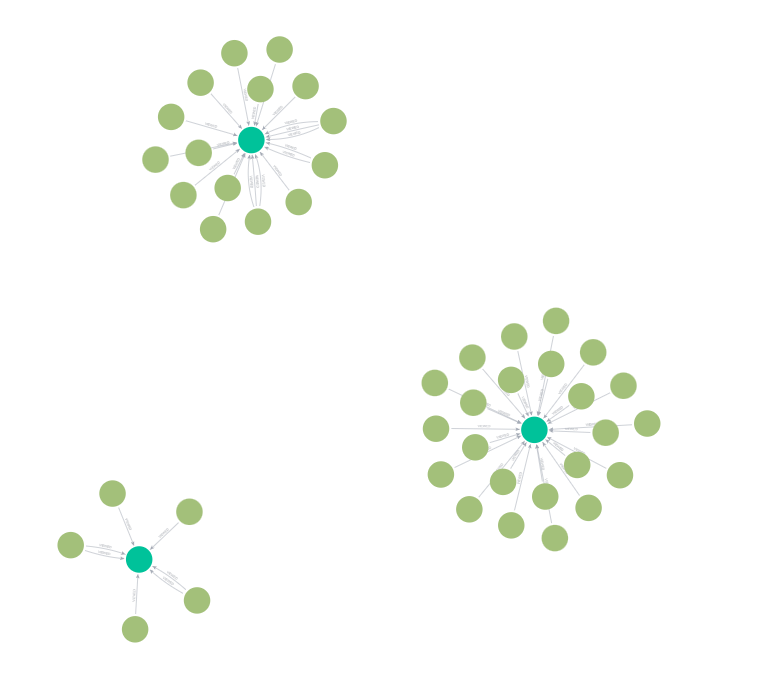

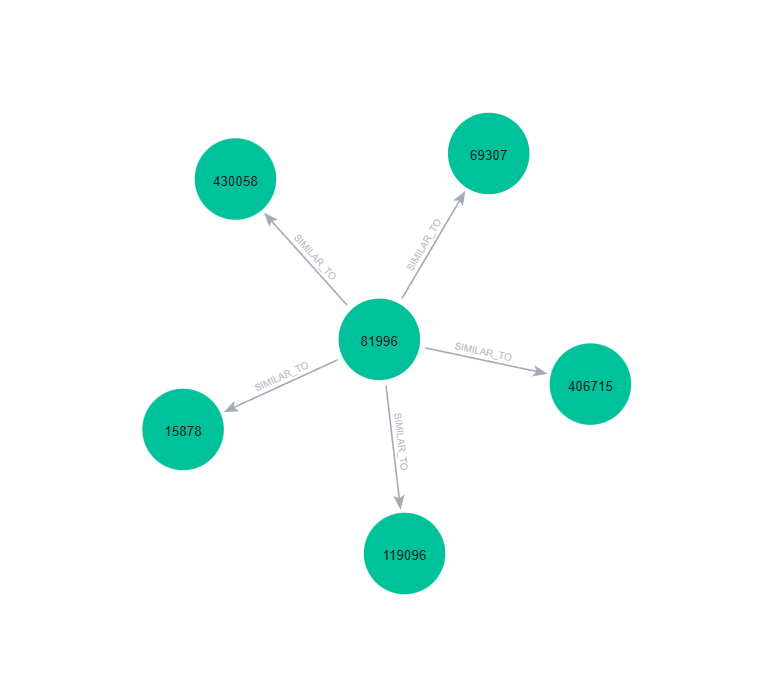

Visualisasi graf setelah penambahan relasi similarity menunjukkan item acuan 81996 terhubung dengan lima item lain melalui relasi `SIMILAR_TO`. Relasi tersebut dibentuk berdasarkan perhitungan *cosine similarity* menggunakan data interaksi pada periode training. Setiap relasi menyimpan nilai kemiripan, metode perhitungan, dan informasi periode data. Visualisasi ini memperlihatkan bahwa hubungan antaritem dapat direpresentasikan secara langsung dalam graf, sehingga item yang memiliki pola interaksi serupa dapat diidentifikasi melalui relasi tersebut.

## 2.2 Analytics
6. Rekomendasi dan evaluasi KNN

### Skrip sumber: `knn_rekomendasi.py`

In [5]:
# Sumber: knn_rekomendasi.py

import pandas as pd
import numpy as np
from scipy.sparse import load_npz

# ==================================================
# 1. KONFIGURASI
# ==================================================
SEED = 42
K = 5
JUMLAH_REKOMENDASI = 5

PATH_TRAINING = "data/folds/training.csv"
PATH_TESTING = "data/folds/testing.csv"
PATH_VSM = "vsm_user_item.npz"
PATH_VISITOR_IDS = "visitor_ids.npy"
PATH_ITEM_IDS = "item_ids.npy"

# ==================================================
# 2. MEMBACA DATA
# ==================================================
print("Membaca data training, testing, dan VSM...")

training = pd.read_csv(PATH_TRAINING)
testing = pd.read_csv(PATH_TESTING)

X = load_npz(PATH_VSM).tocsr()
visitor_ids = np.load(PATH_VISITOR_IDS).astype(int)
item_ids = np.load(PATH_ITEM_IDS).astype(int)

print("Shape VSM:", X.shape)
print("Jumlah visitor:", len(visitor_ids))
print("Jumlah item:", len(item_ids))

visitor_to_idx = {
    int(visitor_id): idx
    for idx, visitor_id in enumerate(visitor_ids)
}

item_to_idx = {
    int(item_id): idx
    for idx, item_id in enumerate(item_ids)
}

# ==================================================
# 3. MENYIAPKAN DATA TRANSAKSI TESTING
# ==================================================
transaksi = testing[
    testing["event"] == "transaction"
].copy()

transaksi["visitorid"] = transaksi["visitorid"].astype(int)
transaksi["itemid"] = transaksi["itemid"].astype(int)

# Item transaksi testing dikelompokkan berdasarkan pengguna.
aktual = (
    transaksi.groupby("visitorid")["itemid"]
    .apply(lambda s: set(s))
    .to_dict()
)

# ==================================================
# 4. MEMILIH PENGGUNA SECARA REPRODUCIBLE
# ==================================================
# Kriteria pemilihan:
# - Memiliki minimal 3 item berbeda pada training.
# - Memiliki transaksi pada testing.
# - Minimal satu item transaksi testing terdapat di VSM
#   dan belum dilihat saat training.
#
# Pemilihan tidak didasarkan pada keberhasilan rekomendasi.

jumlah_item_user = X.getnnz(axis=1)

pengguna_minimal_3 = {
    int(visitor_ids[idx])
    for idx in np.flatnonzero(jumlah_item_user >= 3)
}

kandidat_user = []

for visitor_id, item_testing in aktual.items():

    if visitor_id not in pengguna_minimal_3:
        continue

    if visitor_id not in visitor_to_idx:
        continue

    idx_user = visitor_to_idx[visitor_id]

    item_dilihat = set(X[idx_user].indices.tolist())

    item_testing_idx = {
        item_to_idx[item]
        for item in item_testing
        if item in item_to_idx
    }

    item_baru = item_testing_idx - item_dilihat

    if len(item_baru) > 0:
        kandidat_user.append(visitor_id)

kandidat_user = sorted(set(kandidat_user))

print("\n=== PEMILIHAN PENGGUNA ===")
print("Kriteria item training minimal: 3")
print("Jumlah kandidat pengguna:", len(kandidat_user))

if not kandidat_user:
    raise ValueError(
        "Tidak ada pengguna yang memenuhi kriteria pemilihan."
    )

rng = np.random.default_rng(SEED)
user_terpilih = int(rng.choice(kandidat_user))
indeks_user = visitor_to_idx[user_terpilih]

print("Seed:", SEED)
print("Pengguna terpilih:", user_terpilih)
print("Jumlah item training pengguna:", X[indeks_user].nnz)

# Item yang benar-benar relevan untuk evaluasi:
# item transaksi testing yang belum dilihat saat training
# dan tersedia pada kolom VSM.
item_dilihat_idx = set(X[indeks_user].indices.tolist())

item_relevan_idx = {
    item_to_idx[item]
    for item in aktual[user_terpilih]
    if item in item_to_idx
}

item_relevan_baru_idx = item_relevan_idx - item_dilihat_idx

item_relevan_baru = {
    int(item_ids[idx])
    for idx in item_relevan_baru_idx
}

print("Jumlah item relevan baru pada testing:",
      len(item_relevan_baru))

# ==================================================
# 5. MENGHITUNG COSINE SIMILARITY ANTAR-PENGGUNA
# ==================================================
print("\nMenghitung cosine similarity...")

vektor_user = X[indeks_user]

norm_user = np.sqrt(
    float(vektor_user.multiply(vektor_user).sum())
)

norm_semua_user = np.sqrt(
    np.asarray(X.multiply(X).sum(axis=1)).ravel()
)

dot_product = (X @ vektor_user.T).toarray().ravel()

penyebut = norm_semua_user * norm_user

similarities = np.divide(
    dot_product,
    penyebut,
    out=np.zeros_like(dot_product, dtype=float),
    where=penyebut > 0
)

# Pengguna tidak boleh menjadi tetangganya sendiri.
similarities[indeks_user] = -1

# Hanya pengguna dengan similarity positif.
indeks_valid = np.flatnonzero(similarities > 0)

urutan_valid = indeks_valid[
    np.argsort(similarities[indeks_valid])[::-1]
]

# Tepat K tetangga terdekat atau kurang jika tidak tersedia.
indeks_tetangga = urutan_valid[:K]

print("\n=== TETANGGA TERDEKAT ===")

for nomor, idx in enumerate(indeks_tetangga, start=1):
    print(
        f"{nomor}. Visitor {visitor_ids[idx]} "
        f"| Similarity: {similarities[idx]:.6f} "
        f"| Jumlah item: {X[idx].nnz}"
    )

if len(indeks_tetangga) == 0:
    raise ValueError(
        "Tidak ditemukan tetangga dengan similarity positif."
    )

# ==================================================
# 6. MEMBENTUK REKOMENDASI DARI K TETANGGA
# ==================================================
vektor_tetangga = X[indeks_tetangga]
bobot_tetangga = similarities[indeks_tetangga]

# Skor item adalah jumlah similarity tetangga
# yang berinteraksi dengan item tersebut.
skor_item = np.asarray(
    vektor_tetangga.T @ bobot_tetangga
).ravel()

# Jangan rekomendasikan item yang telah dilihat pengguna.
if item_dilihat_idx:
    skor_item[list(item_dilihat_idx)] = -np.inf

indeks_kandidat = np.flatnonzero(
    np.isfinite(skor_item) & (skor_item > 0)
)

urutan_kandidat = indeks_kandidat[
    np.argsort(skor_item[indeks_kandidat])[::-1]
]

indeks_rekomendasi = urutan_kandidat[:JUMLAH_REKOMENDASI]

rekomendasi = [
    int(item_ids[idx])
    for idx in indeks_rekomendasi
]

print("\n=== HASIL REKOMENDASI ===")
print("Jumlah tetangga yang digunakan:", len(indeks_tetangga))
print("Jumlah kandidat item baru:", len(indeks_kandidat))

for nomor, idx in enumerate(indeks_rekomendasi, start=1):
    print(
        f"{nomor}. Item {item_ids[idx]} "
        f"| Skor: {skor_item[idx]:.6f}"
    )

if not rekomendasi:
    print(
        "Tidak ada item baru dari K tetangga terdekat. "
        "Hasil ini dipertahankan tanpa menambah tetangga."
    )

# ==================================================
# 7. EVALUASI HIT@5 DAN NDCG@5
# ==================================================
rekomendasi5 = rekomendasi[:5]

# Hit@5 = 1 jika minimal satu item relevan muncul di top-5.
hit = int(
    any(item in item_relevan_baru for item in rekomendasi5)
)

# DCG menghitung keuntungan item relevan sesuai peringkat.
dcg = sum(
    1 / np.log2(posisi + 1)
    for posisi, item in enumerate(rekomendasi5, start=1)
    if item in item_relevan_baru
)

# IDCG adalah DCG ideal jika item relevan ditempatkan di depan.
jumlah_relevan_ideal = min(len(item_relevan_baru), 5)

idcg = sum(
    1 / np.log2(posisi + 1)
    for posisi in range(1, jumlah_relevan_ideal + 1)
)

ndcg = dcg / idcg if idcg > 0 else 0.0

print("\n=== EVALUASI ===")
print("Item relevan baru:", sorted(item_relevan_baru))
print("Item rekomendasi:", rekomendasi5)
print("Hit@5:", hit)
print(f"NDCG@5: {ndcg:.6f}")

# ==================================================
# 8. MENYIMPAN HASIL KE CSV
# ==================================================
hasil = pd.DataFrame({
    "visitorid": [user_terpilih] * len(rekomendasi),
    "peringkat": list(range(1, len(rekomendasi) + 1)),
    "itemid": rekomendasi,
    "skor": [
        float(skor_item[item_to_idx[item]])
        for item in rekomendasi
    ]
})

hasil.to_csv("hasil_rekomendasi_knn.csv", index=False)

evaluasi = pd.DataFrame([{
    "visitorid": user_terpilih,
    "jumlah_item_training": int(X[indeks_user].nnz),
    "jumlah_item_relevan": len(item_relevan_baru),
    "jumlah_rekomendasi": len(rekomendasi5),
    "Hit@5": hit,
    "NDCG@5": ndcg,
    "K": K,
    "seed": SEED
}])

evaluasi.to_csv("evaluasi_knn.csv", index=False)

print("\nFile hasil berhasil disimpan:")
print("- hasil_rekomendasi_knn.csv")
print("- evaluasi_knn.csv")


Membaca data training, testing, dan VSM...
Shape VSM: (661487, 169622)
Jumlah visitor: 661487
Jumlah item: 169622

=== PEMILIHAN PENGGUNA ===
Kriteria item training minimal: 3
Jumlah kandidat pengguna: 64
Seed: 42
Pengguna terpilih: 175709
Jumlah item training pengguna: 3
Jumlah item relevan baru pada testing: 1

Menghitung cosine similarity...

=== TETANGGA TERDEKAT ===
1. Visitor 114134 | Similarity: 0.577350 | Jumlah item: 1
2. Visitor 201079 | Similarity: 0.577350 | Jumlah item: 1
3. Visitor 853895 | Similarity: 0.577350 | Jumlah item: 1
4. Visitor 1001225 | Similarity: 0.577350 | Jumlah item: 1
5. Visitor 206734 | Similarity: 0.577350 | Jumlah item: 1

=== HASIL REKOMENDASI ===
Jumlah tetangga yang digunakan: 5
Jumlah kandidat item baru: 0
Tidak ada item baru dari K tetangga terdekat. Hasil ini dipertahankan tanpa menambah tetangga.

=== EVALUASI ===
Item relevan baru: [228083]
Item rekomendasi: []
Hit@5: 0
NDCG@5: 0.000000

File hasil berhasil disimpan:
- hasil_rekomendasi_knn.cs

### Interpretasi Hasil Rekomendasi KNN dan Evaluasi

Berdasarkan hasil pemrosesan, matriks VSM User-Item memiliki dimensi 661.487 visitor dan 169.622 item. Dari 64 pengguna yang memenuhi kriteria pemilihan, pengguna dengan ID 175709 terpilih menggunakan seed 42. Pengguna tersebut memiliki tiga item berbeda pada data training dan satu item relevan baru pada data testing, yaitu item 228083.

Sistem KNN berhasil menemukan lima tetangga terdekat, yaitu visitor 114134, 201079, 853895, 1001225, dan 206734. Masing-masing memiliki nilai cosine similarity sebesar 0,577350 terhadap pengguna target. Namun, setiap tetangga hanya memiliki satu item dalam matriks VSM.

Hasil perhitungan menunjukkan bahwa tidak terdapat kandidat item baru yang dapat direkomendasikan dari kelima tetangga tersebut. Oleh karena itu, sistem tidak menghasilkan rekomendasi item dan tetap mempertahankan hasil tersebut tanpa menambah jumlah tetangga secara otomatis.

Evaluasi menghasilkan nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,000000. Nilai Hit@5 sebesar 0 menunjukkan bahwa tidak ada item relevan yang berhasil ditemukan dalam daftar rekomendasi. Sementara itu, NDCG@5 bernilai nol karena tidak ada item relevan yang ditempatkan dalam daftar rekomendasi.

Hasil ini menunjukkan bahwa KNN berbasis cosine similarity pada data interaksi *view* belum mampu memberikan rekomendasi yang relevan untuk pengguna yang diuji. Salah satu keterbatasan yang terlihat adalah sedikitnya riwayat interaksi pada tetangga terdekat, sehingga tidak tersedia kandidat item baru yang dapat disarankan. Hasil tersebut perlu dilaporkan secara objektif sebagai temuan eksperimen.

### Skrip sumber: `evaluasi_knn_semua.py`

In [6]:
# Sumber: evaluasi_knn_semua.py

import pandas as pd
import numpy as np
from scipy.sparse import load_npz

# ==================================================
# 1. KONFIGURASI
# ==================================================
K = 5
TOP_N = 5
MIN_ITEM_TRAINING = 3

PATH_TESTING = "data/folds/testing.csv"
PATH_VSM = "vsm_user_item.npz"
PATH_VISITOR_IDS = "visitor_ids.npy"
PATH_ITEM_IDS = "item_ids.npy"

# ==================================================
# 2. MEMBACA VSM DAN DATA TESTING
# ==================================================
print("Membaca VSM dan data testing...")

X = load_npz(PATH_VSM).tocsr()
visitor_ids = np.load(PATH_VISITOR_IDS).astype(int)
item_ids = np.load(PATH_ITEM_IDS).astype(int)

testing = pd.read_csv(PATH_TESTING)

visitor_to_idx = {
    int(visitor_id): idx
    for idx, visitor_id in enumerate(visitor_ids)
}
item_to_idx = {
    int(item_id): idx
    for idx, item_id in enumerate(item_ids)
}

print("Shape VSM:", X.shape)

# ==================================================
# 3. MENYIAPKAN ITEM RELEVAN PADA TESTING
# ==================================================
transaksi = testing[
    testing["event"] == "transaction"
].copy()

transaksi["visitorid"] = transaksi["visitorid"].astype(int)
transaksi["itemid"] = transaksi["itemid"].astype(int)

aktual = (
    transaksi.groupby("visitorid")["itemid"]
    .apply(lambda s: set(s))
    .to_dict()
)

# ==================================================
# 4. MENENTUKAN POPULASI EVALUASI
# ==================================================
# Syarat:
# - minimal 3 item berbeda pada VSM training;
# - memiliki transaksi testing;
# - minimal satu item transaksi testing tersedia di VSM
#   dan belum dilihat pada training.
#
# Pengguna tidak dipilih berdasarkan keberhasilan rekomendasi.

jumlah_item_user = X.getnnz(axis=1)

pengguna_memadai = {
    int(visitor_ids[idx])
    for idx in np.flatnonzero(
        jumlah_item_user >= MIN_ITEM_TRAINING
    )
}

kandidat_evaluasi = []

for visitor_id, item_testing in aktual.items():
    if visitor_id not in pengguna_memadai:
        continue

    if visitor_id not in visitor_to_idx:
        continue

    idx_user = visitor_to_idx[visitor_id]
    item_dilihat = set(X[idx_user].indices.tolist())

    item_relevan_idx = {
        item_to_idx[item]
        for item in item_testing
        if item in item_to_idx
    }

    item_relevan_baru_idx = item_relevan_idx - item_dilihat

    if item_relevan_baru_idx:
        kandidat_evaluasi.append(visitor_id)

kandidat_evaluasi = sorted(set(kandidat_evaluasi))

print("\n=== POPULASI EVALUASI ===")
print("Pengguna yang dievaluasi:", len(kandidat_evaluasi))

if not kandidat_evaluasi:
    raise ValueError(
        "Tidak ada pengguna yang memenuhi kriteria evaluasi."
    )

# ==================================================
# 5. MENYIAPKAN NORMA VEKTOR
# ==================================================
# Dihitung sekali agar tidak berulang untuk setiap pengguna.
norm_semua_user = np.sqrt(
    np.asarray(X.multiply(X).sum(axis=1)).ravel()
)

# ==================================================
# 6. EVALUASI KNN PER PENGGUNA
# ==================================================
hasil = []

for nomor, visitor_id in enumerate(kandidat_evaluasi, start=1):
    idx_user = visitor_to_idx[visitor_id]
    vektor_user = X[idx_user]

    item_dilihat = set(vektor_user.indices.tolist())

    # Item relevan = transaksi testing yang baru bagi pengguna
    item_relevan_idx = {
        item_to_idx[item]
        for item in aktual[visitor_id]
        if item in item_to_idx
    } - item_dilihat

    # Cosine similarity antara target dan seluruh pengguna
    norm_user = norm_semua_user[idx_user]

    dot_product = (X @ vektor_user.T).toarray().ravel()
    penyebut = norm_semua_user * norm_user

    similarities = np.divide(
        dot_product,
        penyebut,
        out=np.zeros_like(dot_product, dtype=float),
        where=penyebut > 0
    )

    # Pengguna tidak boleh menjadi tetangganya sendiri
    similarities[idx_user] = -1

    # Ambil tepat K tetangga terdekat yang similarity-nya positif
    indeks_valid = np.flatnonzero(similarities > 0)

    # Urutkan similarity menurun; indeks menjadi pemecah seri
    urutan = indeks_valid[
        np.lexsort((
            indeks_valid,
            -similarities[indeks_valid]
        ))
    ]

    indeks_tetangga = urutan[:K]

    # Skor item dari K tetangga
    if len(indeks_tetangga) > 0:
        vektor_tetangga = X[indeks_tetangga]
        bobot_tetangga = similarities[indeks_tetangga]

        skor_item = np.asarray(
            vektor_tetangga.T @ bobot_tetangga
        ).ravel()
    else:
        skor_item = np.zeros(X.shape[1], dtype=float)

    # Hilangkan item yang sudah dilihat
    if item_dilihat:
        skor_item[list(item_dilihat)] = -np.inf

    indeks_kandidat = np.flatnonzero(
        np.isfinite(skor_item) & (skor_item > 0)
    )

    urutan_item = indeks_kandidat[
        np.lexsort((
            indeks_kandidat,
            -skor_item[indeks_kandidat]
        ))
    ]

    indeks_rekomendasi = urutan_item[:TOP_N]

    rekomendasi = [
        int(item_ids[idx])
        for idx in indeks_rekomendasi
    ]

    # Hit@5
    hit = int(
        any(idx in item_relevan_idx for idx in indeks_rekomendasi)
    )

    # DCG@5
    dcg = sum(
        1 / np.log2(posisi + 1)
        for posisi, idx in enumerate(indeks_rekomendasi, start=1)
        if idx in item_relevan_idx
    )

    # IDCG@5
    jumlah_relevan_ideal = min(len(item_relevan_idx), TOP_N)

    idcg = sum(
        1 / np.log2(posisi + 1)
        for posisi in range(1, jumlah_relevan_ideal + 1)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0

    hasil.append({
        "visitorid": visitor_id,
        "jumlah_item_training": int(vektor_user.nnz),
        "jumlah_tetangga": len(indeks_tetangga),
        "jumlah_item_relevan": len(item_relevan_idx),
        "jumlah_rekomendasi": len(rekomendasi),
        "item_rekomendasi": str(rekomendasi),
        "Hit@5": hit,
        "NDCG@5": ndcg
    })

    if nomor % 10 == 0 or nomor == len(kandidat_evaluasi):
        print(
            f"Progres: {nomor}/{len(kandidat_evaluasi)} pengguna"
        )

# ==================================================
# 7. MENYIMPAN HASIL PER PENGGUNA
# ==================================================
df_hasil = pd.DataFrame(hasil)
df_hasil.to_csv(
    "hasil_evaluasi_knn_semua.csv",
    index=False
)

# ==================================================
# 8. RINGKASAN EVALUASI
# ==================================================
jumlah_pengguna = len(df_hasil)

jumlah_dapat_rekomendasi = int(
    (df_hasil["jumlah_rekomendasi"] > 0).sum()
)

ringkasan = pd.DataFrame([{
    "jumlah_pengguna_dievaluasi": jumlah_pengguna,
    "jumlah_pengguna_dapat_rekomendasi": jumlah_dapat_rekomendasi,
    "cakupan_rekomendasi": (
        jumlah_dapat_rekomendasi / jumlah_pengguna
    ),
    "rata_rata_Hit@5": df_hasil["Hit@5"].mean(),
    "rata_rata_NDCG@5": df_hasil["NDCG@5"].mean(),
    "K": K,
    "TOP_N": TOP_N,
    "minimal_item_training": MIN_ITEM_TRAINING
}])

ringkasan.to_csv(
    "ringkasan_evaluasi_knn.csv",
    index=False
)

print("\n=== RINGKASAN EVALUASI KNN ===")
print("Pengguna dievaluasi:", jumlah_pengguna)
print("Pengguna mendapat rekomendasi:", jumlah_dapat_rekomendasi)
print(
    "Cakupan rekomendasi: "
    f"{jumlah_dapat_rekomendasi / jumlah_pengguna:.4f}"
)
print(f"Rata-rata Hit@5: {df_hasil['Hit@5'].mean():.6f}")
print(f"Rata-rata NDCG@5: {df_hasil['NDCG@5'].mean():.6f}")

print("\nFile tersimpan:")
print("- hasil_evaluasi_knn_semua.csv")
print("- ringkasan_evaluasi_knn.csv")


Membaca VSM dan data testing...
Shape VSM: (661487, 169622)

=== POPULASI EVALUASI ===
Pengguna yang dievaluasi: 64
Progres: 10/64 pengguna
Progres: 20/64 pengguna
Progres: 30/64 pengguna
Progres: 40/64 pengguna
Progres: 50/64 pengguna
Progres: 60/64 pengguna
Progres: 64/64 pengguna

=== RINGKASAN EVALUASI KNN ===
Pengguna dievaluasi: 64
Pengguna mendapat rekomendasi: 30
Cakupan rekomendasi: 0.4688
Rata-rata Hit@5: 0.000000
Rata-rata NDCG@5: 0.000000

File tersimpan:
- hasil_evaluasi_knn_semua.csv
- ringkasan_evaluasi_knn.csv


Evaluasi KNN pada Seluruh Pengguna

Evaluasi dilakukan terhadap 64 pengguna yang memenuhi kriteria penelitian. Matriks VSM yang digunakan memiliki dimensi 661.487 visitor dan 169.622 item. Setiap pengguna dievaluasi menggunakan metode K-Nearest Neighbors dengan maksimal lima tetangga terdekat dan maksimal lima rekomendasi item.

Hasil evaluasi menunjukkan bahwa hanya 30 dari 64 pengguna yang memperoleh rekomendasi. Dengan demikian, cakupan rekomendasi (recommendation coverage) mencapai 0,4688 atau 46,88%. Sementara itu, 34 pengguna lainnya tidak memperoleh rekomendasi karena sistem tidak menemukan kandidat item baru yang memenuhi kriteria.

Rata-rata Hit@5 sebesar 0,000000 dan rata-rata NDCG@5 sebesar 0,000000. Artinya, tidak ada pengguna dalam populasi evaluasi yang memperoleh item transaksi relevan pada lima rekomendasi teratas. Dengan kata lain, meskipun sistem berhasil menghasilkan rekomendasi untuk sebagian pengguna, rekomendasi tersebut belum sesuai dengan item transaksi baru yang digunakan sebagai acuan evaluasi.

Hasil ini menunjukkan bahwa metode KNN berbasis cosine similarity pada matriks interaksi view memiliki keterbatasan dalam menghasilkan rekomendasi yang relevan. Pola item yang dilihat oleh pengguna lain belum tentu mencerminkan item yang kemudian dibeli. Selain itu, riwayat interaksi yang terbatas dapat menyebabkan kandidat rekomendasi tidak tersedia.

Oleh karena itu, efektivitas metode tidak cukup dinilai dari keberhasilan menghasilkan rekomendasi. Cakupan rekomendasi sebesar 46,88% perlu dipertimbangkan bersama nilai Hit@5 dan NDCG@5 yang masih nol. Temuan ini menjadi dasar untuk membahas keterbatasan KNN pada data Retail Rocket serta kemungkinan pengembangan menggunakan metode atau fitur tambahan.

### Skrip sumber: `bandingkan_baseline.py`

In [7]:
# Sumber: bandingkan_baseline.py

import pandas as pd
import numpy as np
from scipy.sparse import load_npz

TOP_N = 5

# Baca data
training = pd.read_csv("data/folds/training.csv")
testing = pd.read_csv("data/folds/testing.csv")
X = load_npz("vsm_user_item.npz").tocsr()

visitor_ids = np.load("visitor_ids.npy").astype(int)
item_ids = np.load("item_ids.npy").astype(int)

visitor_to_idx = {int(v): i for i, v in enumerate(visitor_ids)}
item_to_idx = {int(v): i for i, v in enumerate(item_ids)}

# Baseline: item paling sering dilihat pada training
# Hitung frekuensi dari pasangan visitor-item unik pada VSM
popularitas = np.asarray(X.sum(axis=0)).ravel()
urutan_populer = np.argsort(-popularitas)
item_populer = [int(item_ids[i]) for i in urutan_populer]

# Transaksi aktual pada testing
transaksi = testing[testing["event"] == "transaction"].copy()
transaksi["visitorid"] = transaksi["visitorid"].astype(int)
transaksi["itemid"] = transaksi["itemid"].astype(int)

aktual = (
    transaksi.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Gunakan kelompok evaluasi yang sama dengan KNN
knn = pd.read_csv("hasil_evaluasi_knn_semua.csv")
hasil = []

for _, baris in knn.iterrows():
    user = int(baris["visitorid"])
    idx_user = visitor_to_idx[user]

    item_dilihat = set(
        int(item_ids[i]) for i in X[idx_user].indices
    )

    relevan = {
        item for item in aktual.get(user, set())
        if item in item_to_idx and item not in item_dilihat
    }

    rekomendasi = [
        item for item in item_populer
        if item not in item_dilihat
    ][:TOP_N]

    hit = int(bool(set(rekomendasi) & relevan))

    dcg = sum(
        1 / np.log2(posisi + 1)
        for posisi, item in enumerate(rekomendasi, start=1)
        if item in relevan
    )

    idcg = sum(
        1 / np.log2(posisi + 1)
        for posisi in range(1, min(len(relevan), TOP_N) + 1)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0

    hasil.append({
        "visitorid": user,
        "item_rekomendasi_baseline": str(rekomendasi),
        "jumlah_relevan": len(relevan),
        "Hit@5": hit,
        "NDCG@5": ndcg
    })

df = pd.DataFrame(hasil)
df.to_csv("hasil_baseline_popularitas.csv", index=False)

print("=== BASELINE POPULARITAS ===")
print("Jumlah pengguna:", len(df))
print(f"Rata-rata Hit@5: {df['Hit@5'].mean():.6f}")
print(f"Rata-rata NDCG@5: {df['NDCG@5'].mean():.6f}")
print("\nFile tersimpan: hasil_baseline_popularitas.csv")


=== BASELINE POPULARITAS ===
Jumlah pengguna: 64
Rata-rata Hit@5: 0.015625
Rata-rata NDCG@5: 0.002050

File tersimpan: hasil_baseline_popularitas.csv


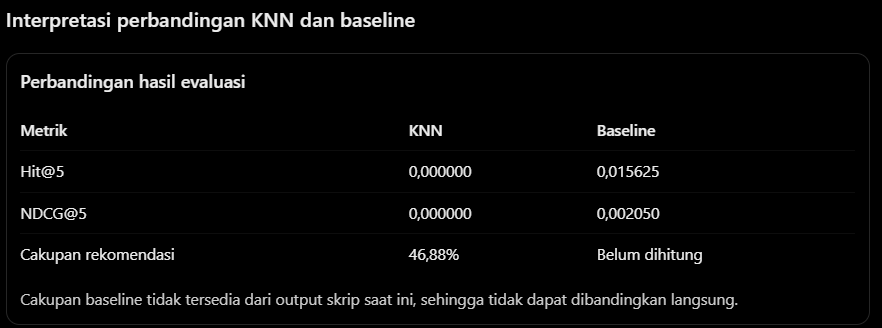

### Interpretasi Hasil Evaluasi Baseline Popularitas

Evaluasi baseline popularitas dilakukan terhadap 64 pengguna yang sama dengan populasi evaluasi KNN. Metode ini merekomendasikan lima item terpopuler berdasarkan jumlah visitor unik pada data training, dengan mengecualikan item yang telah dilihat oleh pengguna target.

Hasil evaluasi menunjukkan rata-rata Hit@5 sebesar 0,015625 dan rata-rata NDCG@5 sebesar 0,002050. Nilai Hit@5 tersebut setara dengan 1,5625% pengguna yang memperoleh setidaknya satu item transaksi relevan dalam lima rekomendasi teratas. Sementara itu, nilai NDCG@5 menunjukkan bahwa relevansi rekomendasi yang dihasilkan masih rendah.

Hasil ini memperlihatkan bahwa pendekatan popularitas dapat menemukan item relevan pada sebagian kecil pengguna. Meskipun demikian, kinerja baseline masih terbatas karena popularitas item tidak selalu mencerminkan kebutuhan atau preferensi individual pengguna.

### Interpretasi Perbandingan KNN dan Baseline Popularitas

Berdasarkan hasil evaluasi terhadap 64 pengguna, metode KNN memperoleh rata-rata Hit@5 sebesar 0,000000 dan NDCG@5 sebesar 0,000000. Sementara itu, baseline popularitas memperoleh Hit@5 sebesar 0,015625 dan NDCG@5 sebesar 0,002050.

Hasil tersebut menunjukkan bahwa baseline popularitas memiliki kinerja lebih baik daripada KNN pada kedua metrik evaluasi. Baseline berhasil menemukan setidaknya satu item transaksi relevan pada satu dari 64 pengguna, sedangkan KNN tidak menemukan item relevan pada lima rekomendasi teratas untuk seluruh pengguna yang dievaluasi.

Perbedaan ini menunjukkan bahwa penggunaan kemiripan antarvisitor berdasarkan interaksi *view* belum memberikan keuntungan dibandingkan rekomendasi berdasarkan popularitas item pada eksperimen ini. Salah satu kemungkinan penyebabnya adalah keterbatasan riwayat interaksi pada tetangga terdekat, sehingga item yang dapat digunakan untuk menyusun rekomendasi menjadi terbatas.

Meskipun baseline menunjukkan hasil yang relatif lebih baik, nilai Hit@5 dan NDCG@5 keduanya masih rendah. Dengan demikian, kedua pendekatan belum menunjukkan kemampuan rekomendasi yang memadai pada populasi dan skema evaluasi yang digunakan. Temuan ini perlu disampaikan sebagai keterbatasan eksperimen, bukan sebagai bukti bahwa KNN selalu lebih buruk daripada metode popularitas pada semua dataset.

## 7. Kesimpulan dan Keterbatasan

### 7.1 Kesimpulan

Berdasarkan hasil pengolahan dan analisis data Retail Rocket, data interaksi pengguna dengan item berhasil dibagi menjadi periode training dan testing. Data training digunakan untuk membentuk graf interaksi serta matriks *Visitor-Item*, sedangkan data testing digunakan untuk mengevaluasi hasil rekomendasi.

Representasi matriks *Visitor-Item* dengan format sparse menghasilkan matriks berukuran 661.487 × 169.622 dengan 994.219 pasangan unik pengguna dan item. Matriks tersebut kemudian digunakan untuk membentuk proyeksi graf Item-Item. Hasil proyeksi menghasilkan 22.118.370 relasi berarah atau 11.059.185 pasangan item unik tanpa memperhitungkan arah. Nilai *cosine similarity* digunakan untuk mengukur kemiripan antaritem berdasarkan pola interaksi pengguna.

Hasil perhitungan kemiripan berhasil disimpan dalam Neo4j melalui relasi `SIMILAR_TO`. Untuk item acuan 81996, lima item teratas yang memiliki kemiripan tertinggi adalah item 15878, 430058, 69307, 406715, dan 119096, masing-masing dengan nilai *cosine similarity* sekitar 0,707107. Hasil ini menunjukkan bahwa perhitungan kemiripan menggunakan Python dapat diintegrasikan dengan graf Neo4j untuk menyimpan dan menelusuri hubungan antaritem.

Pada tahap rekomendasi, metode K-Nearest Neighbors (KNN) dievaluasi terhadap 64 pengguna yang dipilih secara reproducible. Sebanyak 30 pengguna memperoleh rekomendasi, sehingga cakupan rekomendasi (*recommendation coverage*) mencapai 46,88%. Nilai rata-rata Hit@5 dan NDCG@5 untuk KNN masing-masing sebesar 0 dan 0. Sementara itu, metode baseline popularitas menghasilkan Hit@5 sebesar 0,015625 dan NDCG@5 sebesar 0,002050. Dengan demikian, baseline popularitas memberikan hasil evaluasi yang lebih baik daripada KNN pada pengujian ini, meskipun performa kedua metode masih rendah.

### 7.2 Keterbatasan

Analisis ini memiliki beberapa keterbatasan. Pertama, matriks interaksi menggunakan representasi biner sehingga frekuensi interaksi berulang antara pengguna dan item tidak diperhitungkan secara langsung. Kedua, proyeksi Item-Item menghasilkan banyak pasangan item sehingga membutuhkan sumber daya komputasi dan penyimpanan yang cukup besar. Ketiga, hasil rekomendasi KNN dipengaruhi oleh tingkat kesamaan pengguna dan ketersediaan item kandidat. Pengguna dengan sedikit riwayat interaksi dapat memiliki tetangga yang tidak menghasilkan cukup banyak kandidat rekomendasi.

Selain itu, evaluasi dilakukan pada subset pengguna yang memenuhi kriteria pemilihan, sehingga hasilnya belum tentu mewakili seluruh pengguna dalam dataset. Nilai Hit@5 dan NDCG@5 yang rendah menunjukkan bahwa metode yang digunakan belum berhasil menghasilkan rekomendasi yang relevan secara konsisten pada pengujian ini. Penelitian lanjutan dapat mempertimbangkan penyesuaian pemilihan tetangga, pembentukan kandidat rekomendasi, penggunaan bobot frekuensi interaksi, serta evaluasi pada cakupan pengguna yang lebih luas.

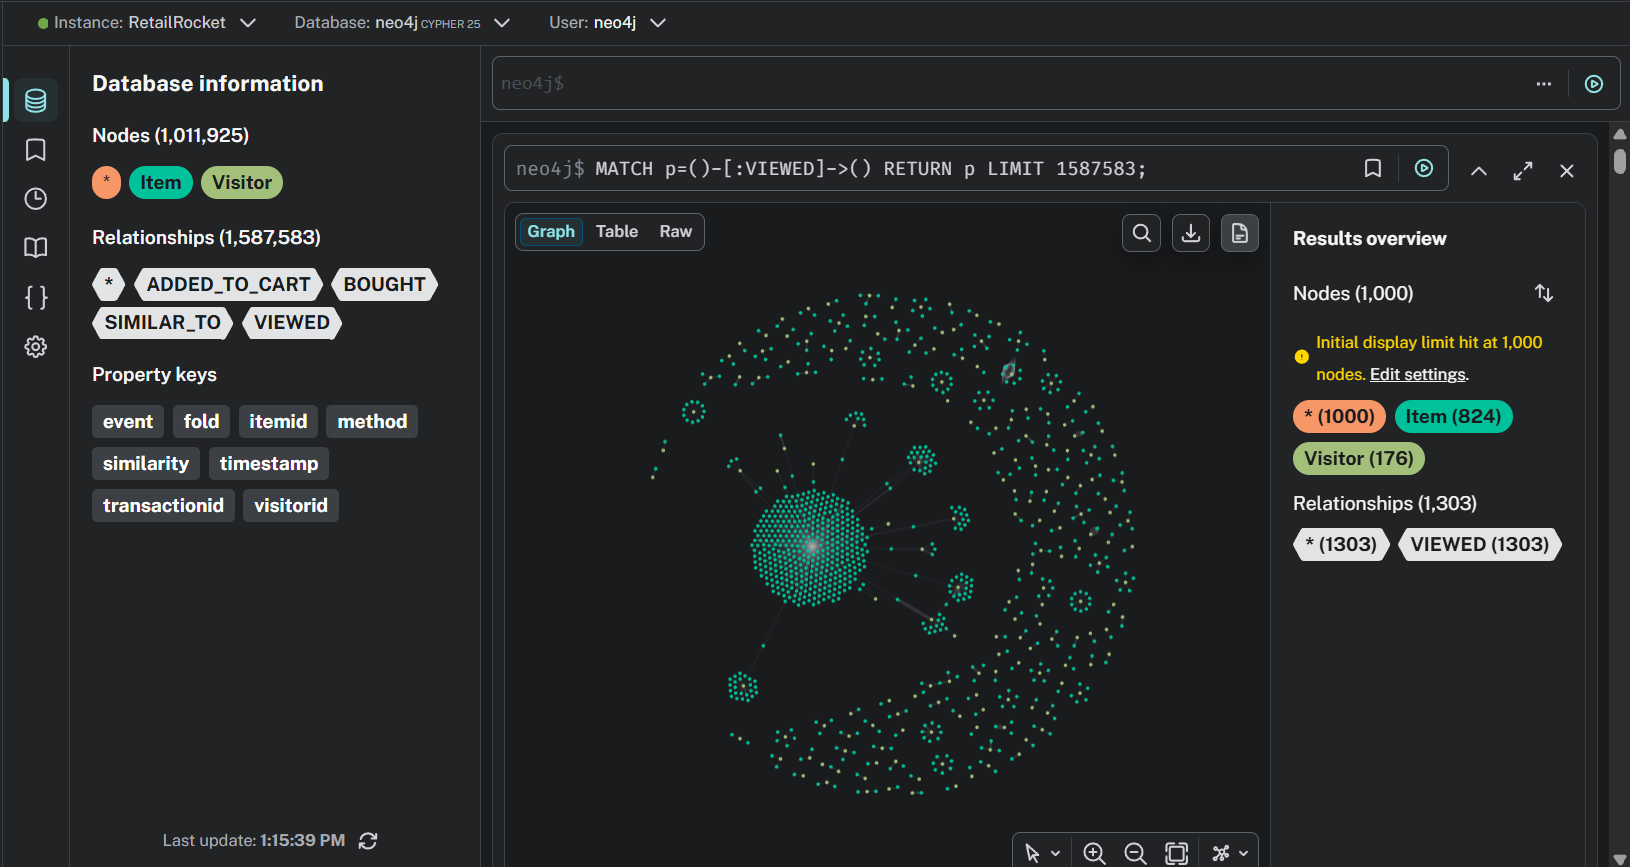

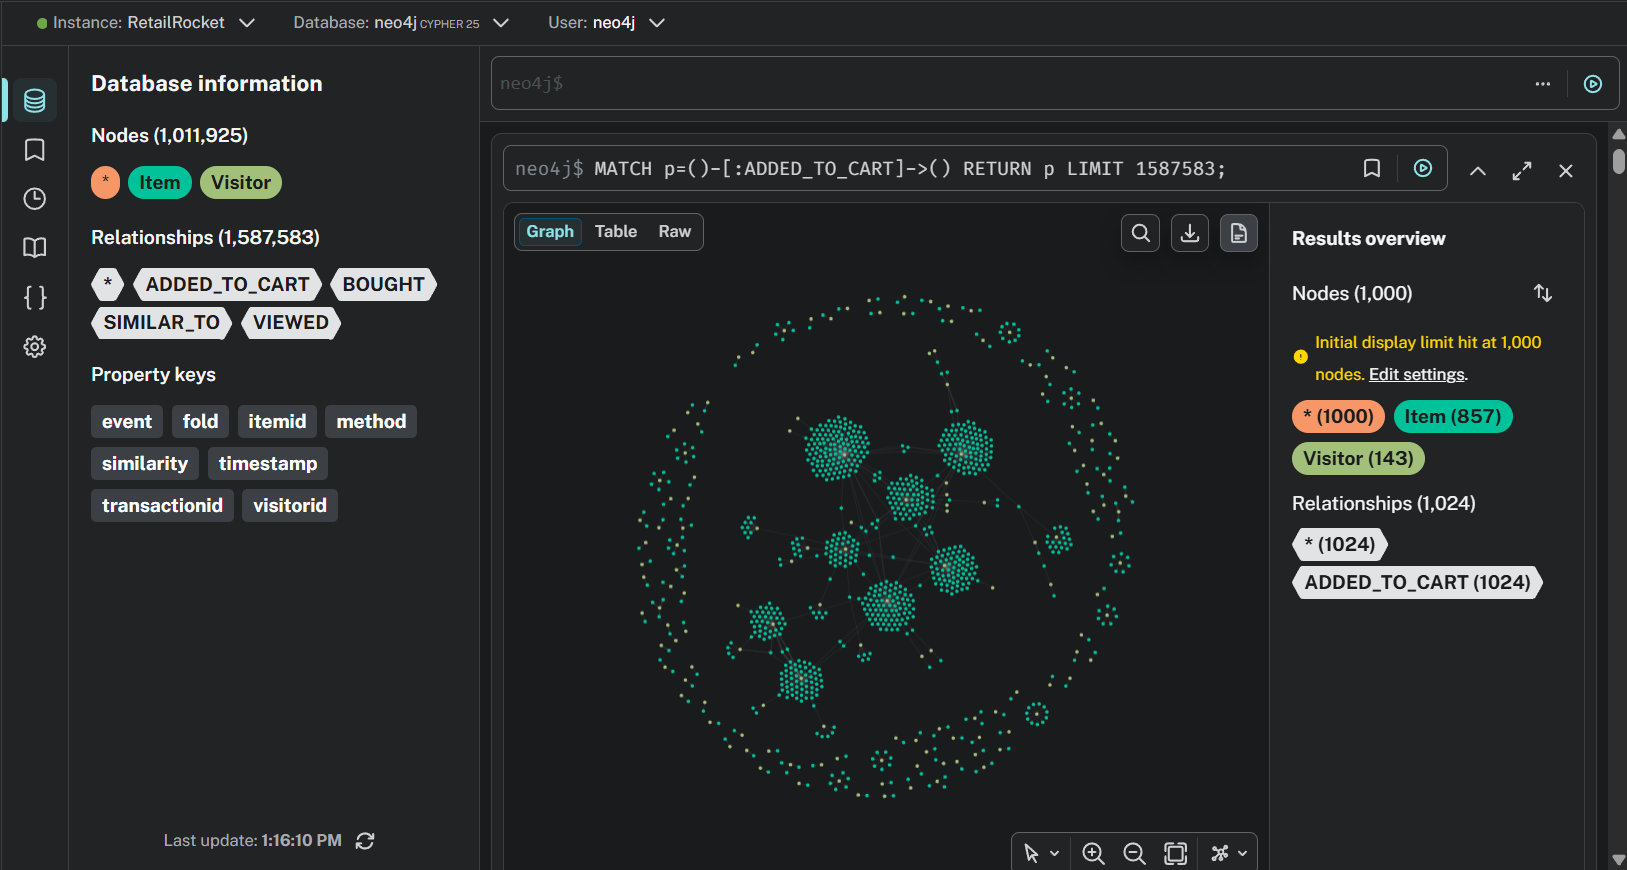

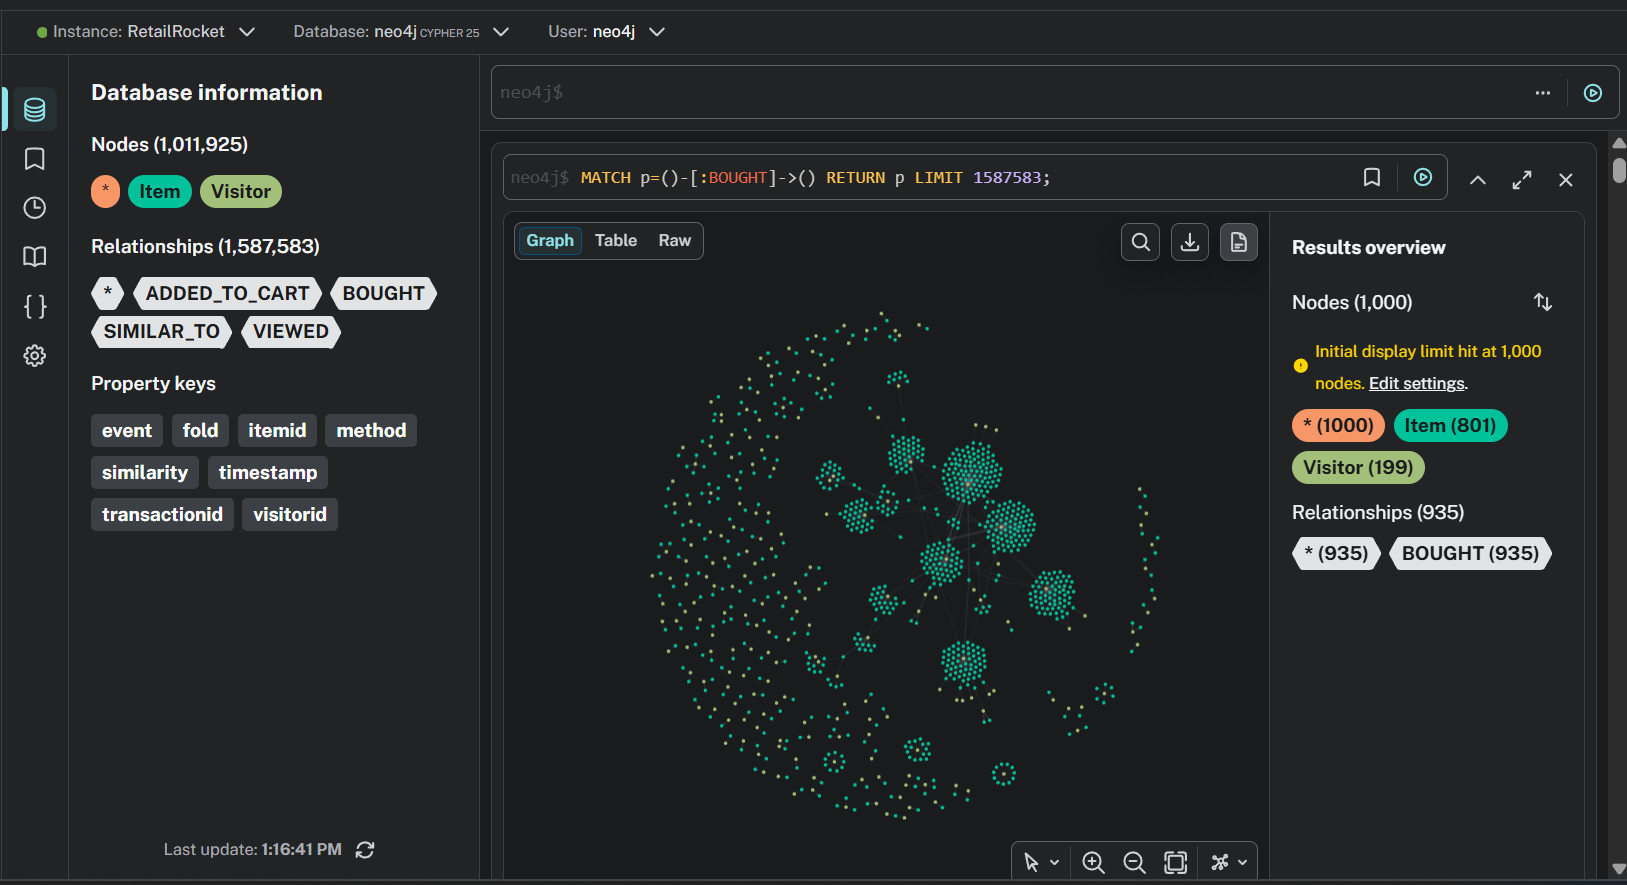

# Graf Pertemanan

In [11]:
from neo4j import GraphDatabase
import getpass

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Masukkan password Neo4j: ")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (b:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(b)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

def print_friends(driver, name):
    records, summary, keys = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend:Person)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="neo4j",
    )

    for record in records:
        print(record["friend_name"])

with GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Teman Arthur:")
    print_friends(driver, "Arthur")



def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (b:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(b)
            """,
            name=name,
            friend_name=friend_name,
        )


def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend:Person)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend_name
            """,
            name=name,
        )

        for record in result:
            print(record["friend_name"])


C:\Users\nafilahanum.alhs\AppData\Local\Temp\ipykernel_22820\1505536985.py:39: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


AttributeError: 'BoltDriver' object has no attribute 'execute_query'